In [ ]:
## Cell 1 — 환경 설치
import os, sys, subprocess
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
assert "transformers" not in sys.modules, "런타임을 재시작한 뒤 다시 실행"
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
    "transformers==5.17.0", "accelerate==1.14.0", "gdown", "pyarrow"])
import torch, transformers, accelerate, numpy as np, pandas as pd
print(torch.__version__, transformers.__version__, accelerate.__version__, np.__version__)
print(torch.cuda.get_device_name(0),
      round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1), "GiB")

2.11.0+cu128 5.17.0 1.14.0 2.1.3
NVIDIA A100-SXM4-40GB 39.5 GiB


In [ ]:
import sys, subprocess, os
import torch, transformers, accelerate, numpy as np, pandas as pd

In [ ]:
## Cell 2 — 설정·경로
import json, random, hashlib, re, time
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/Grad_share/data_share/P9v4')
for d in ['inputs', 'env', 'cb', 'hidden', 'gen', 'folds']:
    (ROOT / d).mkdir(parents=True, exist_ok=True)

CFG = dict(MODEL_ID='meta-llama/Llama-3.1-8B-Instruct', REV_PREFIX='0e9e39f',
           DTYPE='bfloat16', ATTN='sdpa', BS=16, MAX_NEW_TOKENS=192, SEED=SEED,
           PROMPT_VERSION='p8s-v3')   # truncate_answer 버그 수정분 반영
(ROOT / 'env' / 'cfg.json').write_text(json.dumps(CFG, indent=2))

Mounted at /content/drive


201

In [ ]:
## Cell 3 — 입력 데이터 받기·검증
import gdown, requests, importlib.util

FILES = {
    'behavior': ('1RXvW6o552ZNZn1PUMRaf8CEDMIUpqQOr', 'p8s_behavior_v2.csv'),
    'klabels':  ('1LMrQ3R4XWTcBbDn3kk2mR1iTITYw-KFF', 'k_relabel_v2.parquet'),
    'meta':     ('10CiwxEZQfPtW2Gcshibd-Eent5zuq7LR', 'p8s_v2_meta.json'),
    'kaudit':   ('1ZBKNRzlfvIxGWxw81XYEkzKT1qebTorD', 'k_flip_audit_labeled.csv'),
}
P = {}
for k, (fid, name) in FILES.items():
    p = ROOT / 'inputs' / name
    if not p.exists():
        gdown.download(id=fid, output=str(p), quiet=True)
    assert p.exists() and p.stat().st_size > 0, name
    P[k] = p

# 팀 프롬프트 모듈: E11과 같은 commit으로 고정
COMMIT = '733d4e1f398c1eb9649cd9073925c2466111f16d'
pp = ROOT / 'inputs' / 'p8s_prompt.py'
if not pp.exists():
    r = requests.get(f'https://raw.githubusercontent.com/Ontology0/Graduation-Project/'
                     f'{COMMIT}/prompt/p8s_prompt.py', timeout=60)
    r.raise_for_status()
    pp.write_bytes(r.content)
spec = importlib.util.spec_from_file_location('p8s_prompt', pp)
PM = importlib.util.module_from_spec(spec)
spec.loader.exec_module(PM)

# 입력 파일 해시 기록
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
(ROOT / 'env' / 'input_manifest.json').write_text(json.dumps(
    {k: {'file': v.name, 'sha256': sha(v)} for k, v in {**P, 'prompt': pp}.items()}, indent=2))

df = pd.read_csv(P['behavior'])
lab = pd.read_parquet(P['klabels'])
print(df.shape, lab.shape)
print('behavior cols:', df.columns.tolist())
print('klabel cols:', lab.columns.tolist())
print(df.ctx_label.value_counts().to_dict(), '질문 수', df.question.nunique())
print('SYSTEM_PROMPT:', PM.SYSTEM_PROMPT)
print('MAX_NEW_TOKENS', PM.MAX_NEW_TOKENS, '| FEWSHOT', bool(PM.FEWSHOT))
print('module:', [n for n in dir(PM) if not n.startswith('_')])

(1224, 25) (612, 21)
behavior cols: ['question', 'gold', 'prop', 'kside', 'knows', 'A_cb', 'ctx_id', 'ctx_title', 's_wiki_title', 'orig_gold', 'ctx_label', 'ctx_text', 'answer_surface', 'ans_start', 'ans_end', 'wrong_answer', 'answer', 'behavior', 'final_correct', 'gold_list', 'kside_k', 'kside_new', 'kside_corr', 'k_agree', 'cell_k']
klabel cols: ['question', 'gold_list', 'kside', 'knows', 'cb_greedy', 'cb_samples', 'cb_major', 'major_votes', 'knows_new', 'knows_maj', 'k_agree', 'kside_new', 'kside_maj', 'kside_shift', 'prompt_version', 'prompt_md5', 'em_fold', 'kside_vote', 'knows_k', 'kside_k', 'kside_corr']
{'C+': 612, 'C-': 612} 질문 수 612
SYSTEM_PROMPT: You are a question answering system. Answer the question based on the given context. Output the answer string itself and nothing else: no sentence, no explanation, no punctuation, no quotes. Keep it as short as possible (a name or a term).
MAX_NEW_TOKENS 192 | FEWSHOT False
module: ['FEWSHOT', 'MAX_NEW_TOKENS', 'MODEL_ID', 'PROMPT_V

In [ ]:
## Cell 4 — 모델 로드 (revision 고정) + 환경 기록
from huggingface_hub import login, HfApi
from getpass import getpass
from transformers import AutoTokenizer, AutoModelForCausalLM

login(token=getpass('HF token: ').strip(), add_to_git_credential=False)
revs = [c.commit_id for c in HfApi().list_repo_commits(CFG['MODEL_ID'])]
REV = next((r for r in revs if r.startswith(CFG['REV_PREFIX'])), None)
assert REV, 'revision 0e9e39f를 찾지 못함'

TOK = AutoTokenizer.from_pretrained(CFG['MODEL_ID'], revision=REV)
TOK.padding_side = 'left'
if TOK.pad_token_id is None:
    TOK.pad_token = TOK.eos_token

MODEL = AutoModelForCausalLM.from_pretrained(
    CFG['MODEL_ID'], revision=REV, dtype=torch.bfloat16,
    attn_implementation='sdpa', device_map={'': 'cuda:0'}).eval()
for w in MODEL.parameters():
    w.requires_grad_(False)

env = {'python': sys.version, 'torch': torch.__version__,
       'transformers': transformers.__version__, 'accelerate': accelerate.__version__,
       'gpu': torch.cuda.get_device_name(0), 'revision': REV}
(ROOT / 'env' / 'env.json').write_text(json.dumps(env, indent=2))
(ROOT / 'env' / 'requirements_lock.txt').write_text(
    subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                   capture_output=True, text=True).stdout)
print(env)

HF token: ··········


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

{'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'torch': '2.11.0+cu128', 'transformers': '5.17.0', 'accelerate': '1.14.0', 'gpu': 'NVIDIA A100-SXM4-40GB', 'revision': '0e9e39f249a16976918f6564b8830bc894c89659'}


# P0 복구·고정

In [ ]:
## Cell 5 — v3 채점기 (Steering_develop Cell 6·8과 동일)
import unicodedata
from collections import Counter

PP = PM
DECODE_KW = dict(skip_special_tokens=True, clean_up_tokenization_spaces=False)
EOS_IDS = sorted({TOK.eos_token_id, TOK.convert_tokens_to_ids('<|eot_id|>')})

# 이니셜·약어 앞의 마침표에서는 자르지 않음 (Dr., T.S. 등)
ABBR = r"(?<!\bDr)(?<!\bMr)(?<!\bMs)(?<!\bMrs)(?<!\bSt)(?<!\bJr)(?<!\bSr)(?<!\b[A-Z])"
def trunc_v3(raw):
    s = str(raw).strip().split("\n")[0].strip()
    s = re.sub(r"^(answer|the answer is)\s*:?\s*", "", s, flags=re.I)
    if len(s.split()) > 8:
        s = re.split(ABBR + r"\.\s+(?=[A-Z])", s)[0]
    return re.sub(r"[.,;:\s]+$", "", s.strip().strip('"\'')).strip()

fold_ = lambda s: "".join(c for c in unicodedata.normalize("NFKD", PP.norm(s))
                          if not unicodedata.combining(c))
def relaxed(p, golds):          # 완화 매칭: 정확 일치 또는 포함 관계
    p = fold_(p)
    if not p:
        return 0
    return int(any((g := fold_(x)) and (p == g or g in p or p in g) for x in golds))
emv = lambda p, g: int(any(PP.norm(p) == PP.norm(x) for x in g))   # strict EM

for s in ['Dr. Dre', 'T.S. Eliot', 'Answer: Paris.', 'Ronald D. Moore and Brannon Braga']:
    print(repr(s), '→', repr(trunc_v3(s)))

'Dr. Dre' → 'Dr. Dre'
'T.S. Eliot' → 'T.S. Eliot'
'Answer: Paris.' → 'Paris'
'Ronald D. Moore and Brannon Braga' → 'Ronald D. Moore and Brannon Braga'


In [ ]:
## Cell 6 — CB 612 재생성 (원 설정 복제: greedy bs32 + 샘플 bs8×5, T0.7, top_p 0.9, seed 42)
kr = pd.read_parquet(P['klabels'])
gl = [list(g) if not isinstance(g, str) else json.loads(g) for g in kr.gold_list]
cbp = [TOK.apply_chat_template(PP.build_messages_cb(q), tokenize=False, add_generation_prompt=True)
       for q in kr.question]

@torch.no_grad()
def gen_cb(idx, **kw):
    enc = TOK([cbp[i] for i in idx], return_tensors="pt", padding=True,
              add_special_tokens=False).to(MODEL.device)
    return MODEL.generate(**enc, max_new_tokens=PP.MAX_NEW_TOKENS, pad_token_id=TOK.pad_token_id,
                          eos_token_id=EOS_IDS, use_cache=True, **kw)[:, enc.input_ids.shape[1]:]
dec = lambda x: TOK.decode(x, **DECODE_KW)

torch.manual_seed(42)
greedy, samp, t0 = [], [], time.time()
for s in range(0, len(cbp), 32):
    idx = list(range(s, min(s + 32, len(cbp))))
    greedy += [dec(x) for x in gen_cb(idx, do_sample=False)]
    for t in range(0, len(idx), 8):
        sub = idx[t:t + 8]
        q = gen_cb(sub, do_sample=True, temperature=0.7, top_p=0.9, num_return_sequences=5)
        samp += [[dec(x) for x in q[j*5:(j+1)*5]] for j in range(len(sub))]
print(f"생성 {time.time()-t0:.0f}s")

# 자기재현: greedy만 한 번 더 돌려 같은지 확인
g2 = []
for s in range(0, len(cbp), 32):
    g2 += [dec(x) for x in gen_cb(list(range(s, min(s + 32, len(cbp)))), do_sample=False)]

cb = pd.DataFrame({'question': kr.question, 'cb_raw': greedy,
                   'cb_samples_raw': [json.dumps(f, ensure_ascii=False) for f in samp]})
cb['cb_greedy_v3'] = [trunc_v3(x) for x in greedy]
cb['kside_v3'] = np.where([relaxed(p, g) for p, g in zip(cb.cb_greedy_v3, gl)], 'K+', 'K−')
cb['kside_v3em'] = np.where([emv(p, g) for p, g in zip(cb.cb_greedy_v3, gl)], 'K+', 'K−')
cb['sc_v3'] = [max(Counter(PP.norm(trunc_v3(x)) for x in f).values()) / 5 for f in samp]
cb['k_agree_v3'] = [np.mean([emv(trunc_v3(x), g) for x in f]) for f, g in zip(samp, gl)]
cb.to_parquet(ROOT / 'cb' / 'cb_v3.parquet', index=False)

# 복구 판정: 지난 실행 출력과 대조
old_rep = sum(PP.truncate_answer(x) == o for x, o in zip(greedy, kr.cb_greedy.values))
print('① greedy 자기재현       ', sum(a == b for a, b in zip(greedy, g2)), '/ 612   (기대 612)')
print('② 구 저장값 재현(구파서) ', old_rep, '/ 612   (지난 실행 579)')
print('③ K+ 수  v3', (cb.kside_v3 == 'K+').sum(), '| v3em', (cb.kside_v3em == 'K+').sum(),
      '  (기대 346 | 319)')
print('④ kside_k 대비\n', pd.crosstab(kr.kside_k, cb.kside_v3), '\n  (기대 K+→K+ 342, K+→K− 4, K−→K+ 4, K−→K− 262)')

생성 118s
① greedy 자기재현        612 / 612   (기대 612)
② 구 저장값 재현(구파서)  579 / 612   (지난 실행 579)
③ K+ 수  v3 346 | v3em 319   (기대 346 | 319)
④ kside_k 대비
 kside_v3   K+   K−
kside_k           
K+        342    4
K−          4  262 
  (기대 K+→K+ 342, K+→K− 4, K−→K+ 4, K−→K− 262)


In [ ]:
## Cell 7 — 프롬프트·행 manifest·fold (CPU, ~30초)
from sklearn.model_selection import StratifiedGroupKFold
md5 = lambda b: hashlib.md5(b).hexdigest()

m = pd.read_csv(P['behavior'])
m['rid'] = np.arange(len(m))
m['kside_v3'] = m.question.map(dict(zip(cb.question, cb.kside_v3)))
m['cb_greedy_v3'] = m.question.map(dict(zip(cb.question, cb.cb_greedy_v3)))
m['isCm'] = m.ctx_label.eq('C-')
m['cell'] = m.kside_v3 + m.ctx_label.str.replace('-', '−')
m['prompt'] = [TOK.apply_chat_template(PP.build_messages(r.question, r.ctx_text),
               tokenize=False, add_generation_prompt=True) for r in m.itertuples()]
m['n_prompt_tok'] = [len(TOK(p, add_special_tokens=False)['input_ids']) for p in m.prompt]

# 프롬프트 동일성: 지난 v3 기록값과 대조
print('md5(prompt file)', md5(pp.read_bytes()), '(기대 20959a4c…)')
print('md5(SYSTEM)     ', md5(PP.SYSTEM_PROMPT.encode()), '(기대 67fe2590…)')
print('md5(template)   ', md5(TOK.chat_template.encode()), '(기대 81de1619…)')

# fold: 질문 단위 그룹, K×prop 층화 → 같은 질문의 C+/C−는 반드시 같은 fold
qdf = m.drop_duplicates('question')[['question', 'kside_v3', 'prop']].reset_index(drop=True)
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
qfold = {}
for k, (_, te) in enumerate(sgk.split(qdf, qdf.kside_v3 + '|' + qdf.prop, groups=qdf.question)):
    qfold.update({q: k for q in qdf.question.values[te]})
m['fold'] = m.question.map(qfold).astype(int)
assert (m.groupby('question').fold.nunique() == 1).all()

json.dump({'outer': qfold,
           'inner_rule': 'outer i의 inner fold = 나머지 4개 outer fold (w_{-i,-j})',
           'seed': SEED, 'strat': 'kside_v3|prop', 'group': 'question'},
          open(ROOT / 'folds' / 'folds_v4.json', 'w'), ensure_ascii=False, indent=1)
m.drop(columns=['prompt']).to_parquet(ROOT / 'env' / 'row_manifest_v4.parquet', index=False)
m.to_pickle('/content/m.pkl')   # 세션 내 캐시

print(pd.crosstab(m.fold, m.cell))
print('n_prompt_tok 중앙값/최대', int(m.n_prompt_tok.median()), m.n_prompt_tok.max())

md5(prompt file) 20959a4c34203ea0866d030baf23595d (기대 20959a4c…)
md5(SYSTEM)      67fe2590b5780bad95bdfdcfa0aedf98 (기대 67fe2590…)
md5(template)    81de1619b73b2fdd744897ca14b4f0ad (기대 81de1619…)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


cell  K+C+  K+C−  K−C+  K−C−
fold                        
0       72    72    50    50
1       69    69    54    54
2       69    69    53    53
3       73    73    49    49
4       63    63    60    60
n_prompt_tok 중앙값/최대 238 377


In [ ]:
## Cell 8 — 기준선 1224행 생성·채점 (fold별, (n_prompt_tok, rid) 정렬, bs16)
BS = 16
FOLD_ROWS = {k: m[m.fold == k].sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
             for k in range(5)}

@torch.no_grad()
def gen_rows(rids):
    out = {}
    for s in range(0, len(rids), BS):
        b = rids[s:s + BS]
        enc = TOK(m.prompt.values[b].tolist(), return_tensors='pt', padding=True,
                  add_special_tokens=False).to(MODEL.device)
        g = MODEL.generate(**enc, max_new_tokens=PP.MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=TOK.pad_token_id, eos_token_id=EOS_IDS)[:, enc.input_ids.shape[1]:]
        for r, row in zip(b, g.tolist()):
            stop = next((i for i, t in enumerate(row) if t in EOS_IDS), None)
            n = stop if stop is not None else len(row)
            out[int(r)] = (TOK.decode(row[:n], **DECODE_KW), n, json.dumps(row[:n]))
    return out

GQ = dict(zip(kr.question, gl))
GL = [GQ[q] for q in m.question]
assert len(GL) == 1224 and all(len(g) > 0 for g in GL)

def score(df):
    df = df.sort_values('rid').reset_index(drop=True)
    p = [trunc_v3(x) for x in df.raw]
    s = m.answer_surface.fillna('').map(PP.norm).values
    df['pred'] = p
    df['em'] = [emv(x, g) for x, g in zip(p, GL)]
    df['follows_ctx'] = [int(bool(si) and PP.norm(x) == si) for x, si in zip(p, s)]
    df['hit_limit'] = (df.n_tok >= PP.MAX_NEW_TOKENS).astype(int)
    return df

def run_all(tag):
    f = ROOT / 'gen' / f'{tag}.parquet'
    if f.exists():
        return pd.read_parquet(f)
    t0, rec = time.time(), []
    for k in range(5):
        rec += [dict(rid=r, raw=x, n_tok=n, ids=i) for r, (x, n, i) in gen_rows(FOLD_ROWS[k]).items()]
    df = score(pd.DataFrame(rec))
    df.to_parquet(f, index=False)
    print(f'{tag}: {time.time()-t0:.0f}s')
    return df

BASE = run_all('base_p8sv2')
T = BASE.assign(cell=m.cell.values).groupby('cell').agg(
    n=('em', 'size'), EM=('em', 'mean'), follows_ctx=('follows_ctx', 'mean'), hit=('hit_limit', 'mean'))
print(T.round(3))
print('전체 EM', round(BASE.em.mean(), 4), '| C−', round(BASE.em[m.isCm].mean(), 4),
      '| C+', round(BASE.em[~m.isCm].mean(), 4))

base_p8sv2: 56s
        n     EM  follows_ctx  hit
cell                              
K+C+  346  0.876        0.714  0.0
K+C−  346  0.419        0.387  0.0
K−C+  266  0.703        0.605  0.0
K−C−  266  0.056        0.586  0.0
전체 EM 0.531 | C− 0.2614 | C+ 0.8007


In [ ]:
## Cell 9 — golden set (셀당 16 = 64행), 기준선 자기재현
rng = np.random.default_rng(SEED)
GOLD = np.sort(np.concatenate([rng.choice(m.rid[m.cell == c].values, 16, replace=False)
                               for c in sorted(m.cell.unique())]))
def golden_base():
    out = {}
    for k in range(5):
        rk = m.loc[GOLD[m.fold.values[GOLD] == k]].sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
        out.update({r: v[2] for r, v in gen_rows(rk).items()})
    return pd.Series(out).sort_index()

g1, g2 = golden_base(), golden_base()
print('golden 자기재현 불일치:', int((g1 != g2).sum()), '/', len(g1), ' (기대 0)')
pd.DataFrame({'rid': g1.index, 'cond': 'base', 'ids': g1.values}).to_parquet(
    ROOT / 'env' / 'golden_ids.parquet', index=False)

golden 자기재현 불일치: 0 / 64  (기대 0)


In [ ]:
## Cell 10 — hidden 캡처: p8s-v2, 마지막 prefill 토큰, h_out L0–31 (1224×32×4096 fp16, 321MB)
HP = ROOT / 'hidden' / 'p8sv2_h_out.npy'
if HP.exists():
    H = np.load(HP)
else:
    H = np.zeros((len(m), 32, 4096), dtype=np.float16)
    cap = {}
    def mk(L):
        def f(mod, a, out):
            h = out[0] if isinstance(out, (tuple, list)) else out
            cap[L] = h[:, -1, :].float().cpu()
        return f
    hooks = [MODEL.model.layers[L].register_forward_hook(mk(L)) for L in range(32)]
    order = m.sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
    t0 = time.time()
    with torch.no_grad():
        for s in range(0, len(order), BS):
            b = order[s:s + BS]
            enc = TOK(m.prompt.values[b].tolist(), return_tensors='pt', padding=True,
                      add_special_tokens=False).to(MODEL.device)
            MODEL.model(**enc, use_cache=False)      # lm_head 생략 (hidden만 필요)
            for L in range(32):
                H[b, L] = cap[L].numpy().astype(np.float16)
    for h in hooks:
        h.remove()
    np.save(HP, H)
    print(f'{time.time()-t0:.0f}s')

print(H.shape, '| 평균 노름 L0/L14/L31:',
      [round(float(np.linalg.norm(H[:, L].astype(np.float32), axis=1).mean()), 1) for L in (0, 14, 31)])

25s
(1224, 32, 4096) | 평균 노름 L0/L14/L31: [0.8, 8.1, 59.0]


In [ ]:
## Cell 11 — w_v3 (fold별, retain − accept, prop 균형, L8–18) + 강도 기준 MED
p_ = np.array([PP.norm(x) for x in BASE.pred])
s_ = m.answer_surface.fillna('').map(PP.norm).values
c_ = m.cb_greedy_v3.fillna('').map(PP.norm).values
m['acc_x'] = ((s_ != '') & (p_ == s_)).astype(int)                 # 문맥 답을 따름
m['ret_x'] = ((c_ != '') & (c_ != s_) & (p_ == c_)).astype(int)    # CB 답(기억)을 유지
PR, isCm = m.prop.values, m.isCm.values

def pbd(X, pos, neg, min_n=3):
    """prop별 평균차(pos − neg)의 단순평균 → 단위벡터"""
    ds = []
    for q in np.unique(PR[pos | neg]):
        i = PR == q
        if (pos & i).sum() >= min_n and (neg & i).sum() >= min_n:
            ds.append(X[pos & i].mean(0) - X[neg & i].mean(0))
    d = np.mean(ds, 0)
    return d / np.linalg.norm(d), len(ds)

LAY_W = list(range(8, 19))
W3, MED, INFO = {}, {}, []
for k in range(5):
    tr = m.fold.values != k                                  # outer-train만 사용
    ret = tr & isCm & (m.ret_x.values == 1)
    acc = tr & isCm & (m.acc_x.values == 1)
    W3[k], MED[k] = {}, {}
    for L in LAY_W:
        X = H[:, L].astype(np.float32)
        W3[k][L], npr = pbd(X, ret, acc)                      # + 방향 = retain
        MED[k][L] = float(np.median(np.linalg.norm(X[tr], axis=1)))
    INFO.append(dict(fold=k, n_ret=int(ret.sum()), n_acc=int(acc.sum()), props=npr))

np.savez(ROOT / 'hidden' / 'w_v3_v4.npz',
         **{f'w_f{k}_L{L}': W3[k][L] for k in W3 for L in LAY_W},
         **{f'med_f{k}_L{L}': MED[k][L] for k in MED for L in LAY_W})
m[['rid', 'acc_x', 'ret_x']].to_parquet(ROOT / 'hidden' / 'w_groups_v4.parquet', index=False)
print(pd.DataFrame(INFO))
print('fold 간 cos (L16):\n', np.round([[float(W3[a][16] @ W3[b][16]) for b in range(5)] for a in range(5)], 3))

   fold  n_ret  n_acc  props
0     0    119    236     12
1     1    117    232     12
2     2    122    227     12
3     3    118    234     12
4     4    124    231     12
fold 간 cos (L16):
 [[1.    0.959 0.981 0.982 0.964]
 [0.959 1.    0.962 0.962 0.973]
 [0.981 0.962 1.    0.981 0.962]
 [0.982 0.962 0.981 1.    0.959]
 [0.964 0.973 0.962 0.959 1.   ]]


# 부호·hook 검증

In [ ]:
## Cell 12 — P9 steering hook (행별 on/off) + hook 검증 2종
LAY = list(range(14, 19))

class SteerP9:
    """P9: non-pad prefill 전 토큰 + 매 decode 스텝, 행별 gate(0/1)"""
    def __init__(self, layers):
        self.d, self.mask, self.gate = None, None, None
        self.h = [MODEL.model.layers[L].register_forward_hook(self._mk(L)) for L in layers]
    def _mk(self, L):
        def hook(mod, args, out):
            if self.d is None:
                return out
            h = out[0] if isinstance(out, (tuple, list)) else out
            g = self.gate.to(h.dtype)[:, None]                                   # (B,1)
            if h.shape[1] > 1:                                                   # prefill
                h += (self.mask.to(h.dtype)[:, :, None] * g[:, :, None]) * self.d[L]
            else:                                                                # decode
                h[:, -1, :] += g * self.d[L]
            return out
        return hook

ST = SteerP9(LAY)

def set_steer(k, rho, w=None):
    w = W3[k] if w is None else w
    ST.d = {L: torch.as_tensor(rho * MED[k][L] * w[L], device=MODEL.device, dtype=MODEL.dtype)
            for L in LAY}

@torch.no_grad()
def gen_rows_s(rids, gate_of=None):
    out = {}
    for s in range(0, len(rids), BS):
        b = rids[s:s + BS]
        enc = TOK(m.prompt.values[b].tolist(), return_tensors='pt', padding=True,
                  add_special_tokens=False).to(MODEL.device)
        ST.mask = enc.attention_mask
        ST.gate = torch.tensor([1.0 if gate_of is None else float(gate_of[int(r)]) for r in b],
                               device=MODEL.device)
        g = MODEL.generate(**enc, max_new_tokens=PP.MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=TOK.pad_token_id, eos_token_id=EOS_IDS)[:, enc.input_ids.shape[1]:]
        for r, row in zip(b, g.tolist()):
            stop = next((i for i, t in enumerate(row) if t in EOS_IDS), None)
            n = stop if stop is not None else len(row)
            out[int(r)] = (TOK.decode(row[:n], **DECODE_KW), n, json.dumps(row[:n]))
    return out

def golden_steer(rho, gate_of=None):
    out = {}
    for k in range(5):
        rk = m.loc[GOLD[m.fold.values[GOLD] == k]].sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
        set_steer(k, rho)
        out.update({r: v[2] for r, v in gen_rows_s(rk, gate_of).items()})
    ST.d = None
    return pd.Series(out).sort_index()

# (a) hook은 켜져 있지만 ρ=0 → 기준선과 문자열이 같아야 함
z = golden_steer(0.0)
print('(a) ρ=0 vs base 불일치:', int((z != g1).sum()), '/ 64   (기대 0)')

# (b) 같은 배치에서 gate가 꺼진 행은 기준선과 같아야 함
half = {int(r): int(i % 2 == 0) for i, r in enumerate(GOLD)}
hs_ = golden_steer(0.06, half)
off = [r for r in GOLD if half[r] == 0]
on = [r for r in GOLD if half[r] == 1]
print('(b) gate off 행 불일치:', int((hs_[off] != g1[off]).sum()), '/', len(off), '(기대 0)',
      '| on 행 변화:', int((hs_[on] != g1[on]).sum()), '/', len(on), '(0보다 커야 함)')

(a) ρ=0 vs base 불일치: 0 / 64   (기대 0)
(b) gate off 행 불일치: 0 / 32 (기대 0) | on 행 변화: 7 / 32 (0보다 커야 함)


# 파일럿 1조건 실측

In [ ]:
## Cell 13 — 파일럿 + 부호 검증: ρ=±0.06 전체 1224행
QI = m.question.astype('category').cat.codes.values

def run_steer(tag, rho, w=None, gate_of=None):
    f = ROOT / 'gen' / f'{tag}.parquet'
    if f.exists():
        return pd.read_parquet(f)
    t0, rec = time.time(), []
    for k in range(5):
        set_steer(k, rho, w)
        rec += [dict(rid=r, raw=x, n_tok=n, ids=i) for r, (x, n, i) in gen_rows_s(FOLD_ROWS[k], gate_of).items()]
    ST.d = None
    df = score(pd.DataFrame(rec))
    df.to_parquet(f, index=False)
    print(f'{tag}: {time.time()-t0:.0f}s')
    return df

def ci_d(d, sel, B=2000, seed=SEED):
    """질문 cluster bootstrap 95% CI"""
    rng = np.random.default_rng(seed)
    q = QI[sel]
    uq, inv = np.unique(q, return_inverse=True)
    S = np.bincount(inv, weights=d[sel])
    N = np.bincount(inv)
    idx = rng.integers(0, len(uq), (B, len(uq)))
    return np.quantile(S[idx].sum(1) / N[idx].sum(1), [.025, .975])

def summarize(df, name):
    d = df.em.values - BASE.em.values
    r = {'cond': name}
    for lab, sel in [('C−', isCm), ('C+', ~isCm)]:
        lo, hi = ci_d(d, sel)
        r[f'{lab} ΔEM'] = f'{d[sel].mean():+.4f} [{lo:+.3f}, {hi:+.3f}]'
        r[f'{lab} Rec/Dam'] = f'{int((d[sel] == 1).sum())}/{int((d[sel] == -1).sum())}'
    r['C− follows_ctx'] = round(df.follows_ctx[isCm].mean(), 3)
    r['hit'] = round(df.hit_limit.mean(), 3)
    return r

P06 = run_steer('P9_r+0.06', +0.06)
M06 = run_steer('P9_r-0.06', -0.06)
print(pd.DataFrame([{'cond': 'base', 'C− follows_ctx': round(BASE.follows_ctx[isCm].mean(), 3)},
                    summarize(P06, '+0.06 (retain)'), summarize(M06, '−0.06 (accept)')]).to_string(index=False))

# golden set에 steering 조건 추가 (이후 세션 관문용)
gs = golden_steer(0.06)
pd.concat([pd.read_parquet(ROOT / 'env' / 'golden_ids.parquet'),
           pd.DataFrame({'rid': gs.index, 'cond': 'P9_r+0.06', 'ids': gs.values})]).to_parquet(
    ROOT / 'env' / 'golden_ids.parquet', index=False)

P9_r+0.06: 59s
P9_r-0.06: 59s
          cond  C− follows_ctx                   C− ΔEM C− Rec/Dam                   C+ ΔEM C+ Rec/Dam  hit
          base           0.474                      NaN        NaN                      NaN        NaN  NaN
+0.06 (retain)           0.332 +0.1291 [+0.101, +0.158]       83/4 +0.0000 [-0.018, +0.018]      16/16  0.0
−0.06 (accept)           0.624 -0.1683 [-0.199, -0.137]      2/105 -0.0147 [-0.033, +0.005]      12/21  0.0


# B1/B2 강도 곡선

In [ ]:
## Cell 14 — B1/B2 강도 sweep: ρ ∈ ±{0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20}
GRID = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20]

def rep_flag(raw):          # 사전등록 기준: 같은 단어 3-gram이 3회 이상
    w = str(raw).split()
    g = Counter(tuple(w[i:i+3]) for i in range(len(w) - 2))
    return int(any(v >= 3 for v in g.values()))

RES = {0.0: BASE}
for r in GRID:
    for sgn in (+1, -1):
        rho = sgn * r
        RES[rho] = run_steer(f'P9_r{rho:+.2f}', rho)

rows = []
for rho in sorted(RES):
    df = RES[rho]
    d = df.em.values - BASE.em.values
    x = {'rho': rho, 'coef≈': round(rho * 128, 1)}
    for lab, sel in [('Cm', isCm), ('Cp', ~isCm)]:
        lo, hi = ci_d(d, sel)
        x[f'{lab}_dEM'], x[f'{lab}_lo'], x[f'{lab}_hi'] = d[sel].mean(), lo, hi
        x[f'{lab}_Rec'], x[f'{lab}_Dam'] = int((d[sel] == 1).sum()), int((d[sel] == -1).sum())
    x['Cm_follow'] = df.follows_ctx[isCm].mean()
    x['hit'] = df.hit_limit.mean()
    x['rep'] = np.mean([rep_flag(t) for t in df.raw])
    x['collapse'] = bool(x['hit'] > .05 or x['rep'] > .05)
    x['Cp_safe'] = bool(x['Cp_lo'] > -.02)
    rows.append(x)

SW = pd.DataFrame(rows)
SW.to_csv(ROOT / 'gen' / 'B2_sweep_summary.csv', index=False)
print(SW.round(4).to_string(index=False))

P9_r+0.02: 56s
P9_r-0.02: 57s
P9_r+0.04: 56s
P9_r-0.04: 61s
P9_r+0.08: 55s
P9_r-0.08: 60s
P9_r+0.10: 57s
P9_r-0.10: 60s
P9_r+0.12: 115s
P9_r-0.12: 71s
P9_r+0.16: 185s
P9_r-0.16: 108s
P9_r+0.20: 383s
P9_r-0.20: 264s
  rho  coef≈  Cm_dEM   Cm_lo   Cm_hi  Cm_Rec  Cm_Dam  Cp_dEM   Cp_lo   Cp_hi  Cp_Rec  Cp_Dam  Cm_follow    hit    rep  collapse  Cp_safe
-0.20  -25.6 -0.2467 -0.2810 -0.2108       0     151 -0.0801 -0.1095 -0.0507      19      68     0.6667 0.0172 0.0139     False    False
-0.16  -20.5 -0.2451 -0.2794 -0.2108       1     151 -0.0654 -0.0931 -0.0376      18      58     0.6765 0.0041 0.0025     False    False
-0.12  -15.4 -0.2386 -0.2745 -0.2042       1     147 -0.0425 -0.0654 -0.0180      16      42     0.6765 0.0008 0.0008     False    False
-0.10  -12.8 -0.2288 -0.2631 -0.1944       1     141 -0.0343 -0.0556 -0.0130      15      36     0.6732 0.0000 0.0000     False    False
-0.08  -10.2 -0.1977 -0.2304 -0.1650       2     123 -0.0212 -0.0408 -0.0016      13      26     0.6

# B3/B5/B6 셀 분해 + 참 라벨 라우팅 표(제한판)

cell   K+C+  K+C−  K−C+  K−C−
rho                          
-0.20   -44  -137    -5   -14
-0.16   -37  -136    -3   -14
-0.12   -24  -133    -2   -13
-0.10   -20  -128    -1   -12
-0.08   -16  -110     3   -11
-0.06   -11   -92     2   -11
-0.04    -4   -67     0    -7
-0.02    -3   -28     2    -5
 0.00     0     0     0     0
 0.02     2    35     1     6
 0.04     4    54    -2     7
 0.06     3    66    -3    13
 0.08     0    77    -6    17
 0.10    -5    82   -11    19
 0.12   -14    83   -18    20
 0.16   -50    73   -61    18
 0.20   -94    43  -124    15
cell    K+C+   K+C−   K−C+   K−C−
rho                              
-0.20 -0.127 -0.396 -0.019 -0.053
-0.16 -0.107 -0.393 -0.011 -0.053
-0.12 -0.069 -0.384 -0.008 -0.049
-0.10 -0.058 -0.370 -0.004 -0.045
-0.08 -0.046 -0.318  0.011 -0.041
-0.06 -0.032 -0.266  0.008 -0.041
-0.04 -0.012 -0.194  0.000 -0.026
-0.02 -0.009 -0.081  0.008 -0.019
 0.00  0.000  0.000  0.000  0.000
 0.02  0.006  0.101  0.004  0.023
 0.04  0.012  0.156 -0

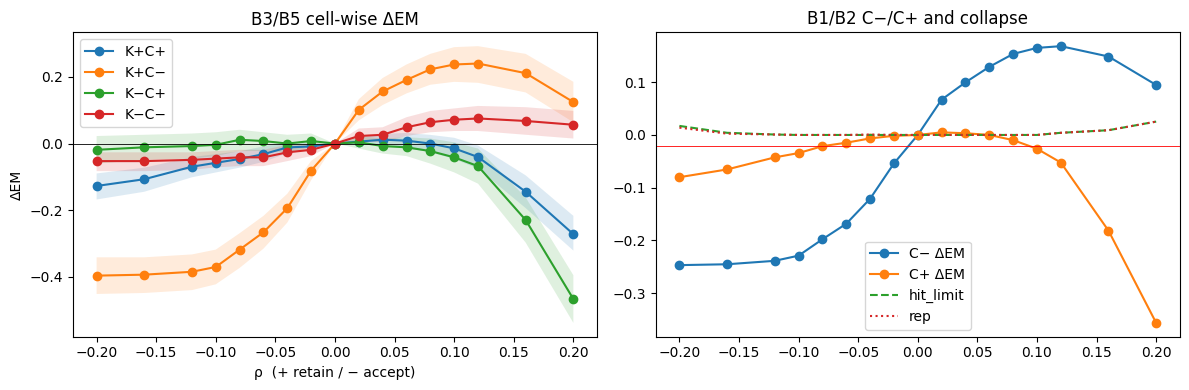

In [ ]:
## Cell 15 — B3/B5/B6: 4셀 분해 (행 수 기준) + 곡선 그림 (CPU)
import matplotlib.pyplot as plt

CELLS = ['K+C+', 'K+C−', 'K−C+', 'K−C−']
cr = []
for rho in sorted(RES):
    d = RES[rho].em.values - BASE.em.values
    for c in CELLS:
        sel = (m.cell == c).values
        lo, hi = ci_d(d, sel)
        cr.append(dict(rho=rho, cell=c, n=int(sel.sum()), dEM=d[sel].mean(), lo=lo, hi=hi,
                       Rec=int((d[sel] == 1).sum()), Dam=int((d[sel] == -1).sum()),
                       Net=int(d[sel].sum())))
CR = pd.DataFrame(cr)
CR.to_csv(ROOT / 'gen' / 'B3_cell_decomp.csv', index=False)
print(CR.pivot(index='rho', columns='cell', values='Net').to_string())            # 셀별 Net (행 수)
print(CR.pivot(index='rho', columns='cell', values='dEM').round(3).to_string())   # 셀별 ΔEM

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in CELLS:
    s = CR[CR.cell == c]
    ax[0].plot(s.rho, s.dEM, marker='o', label=c)
    ax[0].fill_between(s.rho, s.lo, s.hi, alpha=.15)
ax[0].axhline(0, c='k', lw=.6)
ax[0].set_xlabel('ρ  (+ retain / − accept)')
ax[0].set_ylabel('ΔEM')
ax[0].legend()
ax[0].set_title('B3/B5 cell-wise ΔEM')
ax[1].plot(SW.rho, SW.Cm_dEM, marker='o', label='C− ΔEM')
ax[1].plot(SW.rho, SW.Cp_dEM, marker='o', label='C+ ΔEM')
ax[1].plot(SW.rho, SW.hit, ls='--', label='hit_limit')
ax[1].plot(SW.rho, SW.rep, ls=':', label='rep')
ax[1].axhline(-.02, c='r', lw=.6)
ax[1].legend()
ax[1].set_title('B1/B2 C−/C+ and collapse')
plt.tight_layout()
plt.savefig(ROOT / 'gen' / 'B2_B3_curves.png', dpi=150)
plt.show()

In [ ]:
## Cell 16 — 참 라벨 라우팅 표 (action bank 조회) + 이상 행 확인 (CPU)
K = (m.kside_v3 == 'K+').values
def em_of(rho):
    return RES[round(rho, 2)].em.values

def route(rule, rho, rho_a):
    r, a, b = em_of(rho), (em_of(rho_a) if rho_a else BASE.em.values), BASE.em.values
    C = isCm
    if rule == 'always':   return r
    if rule == 'R-C':      return np.where(C, r, b)                               # C−→retain
    if rule == 'R-K':      return np.where(K, r, b)                               # K+→retain
    if rule == 'R-KC':     return np.where(K & C, r, np.where(~K & ~C, a, b))     # K+C−→retain, K−C+→accept
    if rule == 'R-C+acc':  return np.where(C, r, np.where(~K, a, b))              # C−→retain, K−C+→accept

rows = []
for rho in (0.06, 0.10, 0.12):
    for rho_a in (0, -0.04, -0.08):
        for rule in ['always', 'R-C', 'R-K', 'R-KC', 'R-C+acc']:
            if rule in ('always', 'R-C', 'R-K') and rho_a != 0:
                continue                                  # accept 없는 규칙은 1회만
            d = route(rule, rho, rho_a) - BASE.em.values
            x = dict(rho=rho, rho_a=rho_a, rule=rule, all=d.mean())
            for lab, sel in [('Cm', isCm), ('Cp', ~isCm)]:
                lo, hi = ci_d(d, sel)
                x[f'{lab}'] = f'{d[sel].mean():+.3f} [{lo:+.3f},{hi:+.3f}]'
                x[f'{lab}_R/D'] = f'{int((d[sel] == 1).sum())}/{int((d[sel] == -1).sum())}'
            rows.append(x)
LT = pd.DataFrame(rows)
LT.to_csv(ROOT / 'gen' / 'label_routed_table.csv', index=False)
print(LT.round(4).to_string(index=False))

# 사전 판정: (R-KC − R-C) 전체 ΔEM, 동등 한계 ±0.02
print('\n판정: R-KC − R-C (전체 1224행)')
for rho in (0.06, 0.10, 0.12):
    for rho_a in (0, -0.04, -0.08):
        dd = route('R-KC', rho, rho_a) - route('R-C', rho, rho_a)
        lo, hi = ci_d(dd, np.ones(len(m), bool))
        v = ('C만으로 충분' if lo > -.02 and hi < .02
             else 'K 추가 유용' if lo > .02
             else '판정 불가')
        print(f'ρ={rho:.2f} ρa={rho_a:+.2f}  {dd.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]  → {v}')

# 이상 행 직접 확인
show = lambda sel, rho, n=8: print(pd.DataFrame({
    'q': m.question[sel].str[:45], 'gold': [GL[i][:2] for i in np.where(sel)[0]],
    'ctx_ans': m.answer_surface[sel], 'cb': m.cb_greedy_v3[sel],
    'base': BASE.pred[sel], f'ρ{rho}': RES[rho].pred[sel]}).head(n).to_string())

d12 = em_of(0.12) - BASE.em.values
print('\n[K−C− 회복, ρ0.12] — K− 라벨 노이즈인가?')
show((m.cell == 'K−C−').values & (d12 == 1), 0.12)
d20 = em_of(0.20) - BASE.em.values
print('\n[K−C+ 손상, ρ0.20] — 어떤 틀린 답인가?')
show((m.cell == 'K−C+').values & (d20 == -1), 0.2)

 rho  rho_a    rule    all                     Cm Cm_R/D                     Cp Cp_R/D
0.06   0.00  always 0.0645 +0.129 [+0.101,+0.158]   83/4 +0.000 [-0.018,+0.018]  16/16
0.06   0.00     R-C 0.0645 +0.129 [+0.101,+0.158]   83/4 +0.000 [+0.000,+0.000]    0/0
0.06   0.00     R-K 0.0564 +0.108 [+0.083,+0.134]   69/3 +0.005 [-0.008,+0.018]   10/7
0.06   0.00    R-KC 0.0539 +0.108 [+0.083,+0.134]   69/3 +0.000 [+0.000,+0.000]    0/0
0.06   0.00 R-C+acc 0.0645 +0.129 [+0.101,+0.158]   83/4 +0.000 [+0.000,+0.000]    0/0
0.06  -0.04    R-KC 0.0539 +0.108 [+0.083,+0.134]   69/3 +0.000 [-0.011,+0.011]    6/6
0.06  -0.04 R-C+acc 0.0645 +0.129 [+0.101,+0.158]   83/4 +0.000 [-0.011,+0.011]    6/6
0.06  -0.08    R-KC 0.0564 +0.108 [+0.083,+0.134]   69/3 +0.005 [-0.008,+0.020]   11/8
0.06  -0.08 R-C+acc 0.0670 +0.129 [+0.101,+0.158]   83/4 +0.005 [-0.008,+0.020]   11/8
0.10   0.00  always 0.0694 +0.165 [+0.134,+0.199]  110/9 -0.026 [-0.051,+0.002]  27/43
0.10   0.00     R-C 0.0825 +0.165 [+0.134,+

In [ ]:
## Cell 17 — K−C− 회복 행의 샘플 정답률: 숨은 기억 가설 확인
kc = (m.cell == 'K−C−').values
ka = m.question.map(dict(zip(cb.question, cb.k_agree_v3))).values
print('K−C− 회복 행 k_agree 평균:', ka[kc & (d12 == 1)].mean().round(3),
      '| 나머지 K−C−:', ka[kc & (d12 != 1)].mean().round(3), '| n =', int((kc & (d12 == 1)).sum()))

K−C− 회복 행 k_agree 평균: 0.052 | 나머지 K−C−: 0.034 | n = 23


In [ ]:
## Cell 18 — C− 문맥에 gold 별칭이 남아 있는가 (치환 흔적 점검)
ctxn = m.ctx_text.fillna('').map(PP.norm).values
gold_in_ctx = np.array([any(PP.norm(g) and PP.norm(g) in c for g in GL[i]) for i, c in enumerate(ctxn)])

for c in ['K+C−', 'K−C−']:
    sel = (m.cell == c).values
    r, o = sel & (d12 == 1), sel & (d12 != 1)
    print(f'{c}: 회복 행 gold-in-ctx {gold_in_ctx[r].mean():.3f} (n={r.sum()}) '
          f'| 나머지 {gold_in_ctx[o].mean():.3f} (n={o.sum()})')
print('C− 전체 gold-in-ctx 비율:', gold_in_ctx[isCm].mean().round(3))

K+C−: 회복 행 gold-in-ctx 0.137 (n=95) | 나머지 0.195 (n=251)
K−C−: 회복 행 gold-in-ctx 0.087 (n=23) | 나머지 0.045 (n=243)
C− 전체 gold-in-ctx 비율: 0.123


In [ ]:
## Cell 19 — 민감도: gold-in-ctx C− 행 제외 시 주 효과 (CPU, 즉시)
clean = isCm & ~gold_in_ctx
for rho in (0.06, 0.10, 0.12):
    d = em_of(rho) - BASE.em.values
    lo, hi = ci_d(d, clean)
    print(f'ρ={rho:.2f}  C− 전체 {d[isCm].mean():+.4f} | gold-in-ctx 제외 {d[clean].mean():+.4f} '
          f'[{lo:+.3f}, {hi:+.3f}]  (n={clean.sum()})')

ρ=0.06  C− 전체 +0.1291 | gold-in-ctx 제외 +0.1266 [+0.097, +0.158]  (n=537)
ρ=0.10  C− 전체 +0.1650 | gold-in-ctx 제외 +0.1676 [+0.132, +0.203]  (n=537)
ρ=0.12  C− 전체 +0.1683 | gold-in-ctx 제외 +0.1695 [+0.132, +0.207]  (n=537)


In [ ]:
## Cell 21 — (a) R-C@0.12 vs always@0.06 paired CI
##           (b) 같은 선택 절차로 고른 강도끼리 비교 (always vs R-C)
##           (c) K별 강도 R-C 표 (서술용, 선택 안 함)
ALL, b0, FD = np.ones(len(m), bool), BASE.em.values, m.fold.values
RC = lambda rp, rm=None: np.where(isCm & K, em_of(rp),
                          np.where(isCm & ~K, em_of(rp if rm is None else rm), b0))
AO = lambda rho: em_of(rho)

def paired(a, b, name):
    d = a - b
    lo, hi = ci_d(d, ALL)
    print(f'{name}: {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]  '
          f'Net {int(d.sum())}행 (+{int((d == 1).sum())} / −{int((d == -1).sum())})')

print('(a)')
paired(RC(0.12), AO(0.06), 'R-C@0.12 − always@0.06')

# (b) fold i의 ρ는 나머지 fold의 전체 ΔEM으로 선택 → fold i에 적용 (두 arm에 같은 절차)
#     w가 cross-fitted라 strict nested는 아님
GP = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20]
def select_apply(arm):
    out, pick = np.zeros(len(m)), []
    for i in range(5):
        tr, te = FD != i, FD == i
        best = max(GP, key=lambda r: (arm(r)[tr] - b0[tr]).mean())
        pick.append(best)
        out[te] = arm(best)[te]
    return out, pick

ao_sel, ao_pk = select_apply(AO)
rc_sel, rc_pk = select_apply(lambda r: RC(r))
print('\n(b) 선택된 ρ  always:', ao_pk, '| R-C:', rc_pk)
for name, v in [('always(sel)', ao_sel), ('R-C(sel)', rc_sel)]:
    dd = v - b0
    print(f'  {name}: 전체 {dd.mean():+.4f} | C− {dd[isCm].mean():+.4f} | C+ {dd[~isCm].mean():+.4f}')
paired(rc_sel, ao_sel, '  R-C(sel) − always(sel)')
paired(ao_sel, AO(0.06), '  always(sel) − always@0.06')

# (c) C− 안에서 K별로 다른 강도 (서술용 — 최댓값을 고르지 말 것)
G4 = [0.06, 0.10, 0.12, 0.16]
tab = pd.DataFrame([[(RC(a, b) - b0).mean() for b in G4] for a in G4],
                   index=[f'K+C− ρ{a}' for a in G4], columns=[f'K−C− ρ{b}' for b in G4])
print('\n(c) 전체 ΔEM, R-C의 K별 강도 조합 (참 K·C 사용)\n', tab.round(4))

(a)
R-C@0.12 − always@0.06: +0.0196 [+0.0065, +0.0335]  Net 24행 (+54 / −30)

(b) 선택된 ρ  always: [0.08, 0.08, 0.08, 0.08, 0.08] | R-C: [0.1, 0.12, 0.12, 0.12, 0.12]
  always(sel): 전체 +0.0719 | C− +0.1536 | C+ -0.0098
  R-C(sel): 전체 +0.0825 | C− +0.1650 | C+ +0.0000
  R-C(sel) − always(sel): +0.0106 [-0.0041, +0.0253]  Net 13행 (+50 / −37)
  always(sel) − always@0.06: +0.0074 [-0.0016, +0.0172]  Net 9행 (+21 / −12)

(c) 전체 ΔEM, R-C의 K별 강도 조합 (참 K·C 사용)
             K−C− ρ0.06  K−C− ρ0.1  K−C− ρ0.12  K−C− ρ0.16
K+C− ρ0.06      0.0645     0.0694      0.0703      0.0686
K+C− ρ0.1       0.0776     0.0825      0.0833      0.0817
K+C− ρ0.12      0.0784     0.0833      0.0842      0.0825
K+C− ρ0.16      0.0703     0.0752      0.0760      0.0743


In [ ]:
## Cell 22 — K−C− 회복 23행 전체 덤프 (수작업 별칭 점검용 CSV)
sel = (m.cell == 'K−C−').values & (d12 == 1)
dump = pd.DataFrame({
    'rid': m.rid[sel], 'question': m.question[sel],
    'gold_all': [' | '.join(GL[i]) for i in np.where(sel)[0]],
    'ctx_ans': m.answer_surface[sel], 'cb_raw': m.cb_greedy_v3[sel],
    'k_agree': ka[sel], 'gold_in_ctx': gold_in_ctx[sel],
    'base_raw': BASE.raw[sel].values, 'r012_raw': RES[0.12].raw[sel].values,
    'manual': ''})   # 직접 채움: ALIAS(별칭 누락) / TRUE_GAIN(실제 회복) / OTHER
dump.to_csv(ROOT / 'gen' / 'KmCm_recovery_23.csv', index=False)
print(dump.drop(columns='manual').to_string())

       rid                                                                                       question                                                                                                                                                                                                                                                                                   gold_all                       ctx_ans                cb_raw  k_agree  gold_in_ctx           base_raw            r012_raw
666    666                                               In what country is Buckskin Mountain State Park?                                                         United States of America | the United States of America | America | U.S.A. | USA | U.S. | US | the US | the USA | US of A | the United States | U. S. A. | U. S. | the States | the U.S. | 'Merica | U.S | United States | 'Murica                        Guinea              Oklahoma      0.0        False             Guinea       United Sta

In [ ]:
## Cell 23 — A 사전등록 (A1 결과를 보기 전에 저장)
import datetime as dt
PREREG_A = {
 'date': dt.datetime.now(dt.timezone(dt.timedelta(hours=9))).isoformat(),
 'status': 'p8s 내부 탐색. 최종 판단은 외부 재현',
 'gate': 'C 게이트: read 층 L≤13 last-token h_out, 로지스틱 probe. 예측 C−면 retain(P9, L14–18), C+면 no-op',
 'selection_inside_outer_train': ['read 층', 'λ', 'τ', 'ρ ∈ {0.06, 0.08, 0.10, 0.12}'],
 'selection_objective': 'outer-train 전체 ΔEM 최대, 단 C+ ΔEM 하한 > −0.02 (안전 제약)',
 'primary': 'C 게이트(selected) − always-on@0.06 (안전 제약 하 always-on 최대), 전체 ΔEM paired CI 하한 > 0',
 'secondary': ['C 게이트 − always-on(같은 절차로 선택, 제약 없음)',
               'C 게이트 − rate-matched random gate',
               'C 게이트 − 참 C 라우팅 (격차)'],
 'report_always': ['C−/C+ ΔEM', '4셀 Rec/Dam', 'gate 개방률', 'gold-in-ctx 제외 민감도'],
 'known_before_A': 'B 결과 전부 (Cell 14~22). 참 C 라우팅 (a) +0.0196 유의, (b) +0.0106 비유의',
 'eval_path': 'OOF 예측 C → action bank 조회. 상위 설정만 실제 원패스 재생성으로 확인',
}
json.dump(PREREG_A, open(ROOT / 'env' / 'prereg_A.json', 'w'), ensure_ascii=False, indent=1)
print('저장 md5:', md5(open(ROOT / 'env' / 'prereg_A.json', 'rb').read()))

저장 md5: f114ed6e5119e49a0ec4656c859ac1bb


In [ ]:
## 종료 전 저장
json.dump({'a_RC012_vs_AO006': '+0.0196 [+0.0065, +0.0335] Net 24',
           'b_pick_always': ao_pk, 'b_pick_RC': rc_pk,
           'b_RCsel_vs_AOsel': '+0.0106 [-0.0041, +0.0253] Net 13',
           'b_AOsel_vs_AO006': '+0.0074 [-0.0016, +0.0172] Net 9',
           'c_table': tab.round(4).to_dict()},
          open(ROOT / 'gen' / 'cell21_results.json', 'w'), ensure_ascii=False, indent=1)
drive.flush_and_unmount()   # Drive 쓰기 완료 보장
print('저장·동기화 완료')

저장·동기화 완료


# A1 층별 probe

In [ ]:
## Cell R — 세션 복원 + golden 관문 (Cell 1~5 실행 후)
md5 = lambda b: hashlib.md5(b).hexdigest()
BS = 16

# ── 라벨·manifest·fold
kr = pd.read_parquet(P['klabels'])
gl = [list(g) if not isinstance(g, str) else json.loads(g) for g in kr.gold_list]
cb = pd.read_parquet(ROOT / 'cb' / 'cb_v3.parquet')
assert (cb.question.values == kr.question.values).all() and (cb.kside_v3 == 'K+').sum() == 346
m = pd.read_csv(P['behavior'])
m['rid'] = np.arange(len(m))
man = pd.read_parquet(ROOT / 'env' / 'row_manifest_v4.parquet')
assert (man.question.values == m.question.values).all() and (man.ctx_label.values == m.ctx_label.values).all()
for c in ['kside_v3', 'cb_greedy_v3', 'isCm', 'cell', 'n_prompt_tok', 'fold']:
    m[c] = man[c].values
qfold = json.load(open(ROOT / 'folds' / 'folds_v4.json'))['outer']
assert (m.question.map(qfold).values == m.fold.values).all()
m['prompt'] = [TOK.apply_chat_template(PP.build_messages(r.question, r.ctx_text),
               tokenize=False, add_generation_prompt=True) for r in m.itertuples()]
assert all(len(TOK(p, add_special_tokens=False)['input_ids']) == n for p, n in zip(m.prompt, m.n_prompt_tok))

isCm = m.isCm.values.astype(bool)
PR, FOLD = m.prop.values, m.fold.values
K = (m.kside_v3 == 'K+').values
QI = m.question.astype('category').cat.codes.values
GQ = dict(zip(kr.question, gl))
GL = [GQ[q] for q in m.question]
FOLD_ROWS = {k: m[m.fold == k].sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
             for k in range(5)}

def score(df):
    df = df.sort_values('rid').reset_index(drop=True)
    p = [trunc_v3(x) for x in df.raw]
    s = m.answer_surface.fillna('').map(PP.norm).values
    df['pred'] = p
    df['em'] = [emv(x, g) for x, g in zip(p, GL)]
    df['follows_ctx'] = [int(bool(si) and PP.norm(x) == si) for x, si in zip(p, s)]
    df['hit_limit'] = (df.n_tok >= PP.MAX_NEW_TOKENS).astype(int)
    return df

# ── 생성 결과 (action bank)
BASE = pd.read_parquet(ROOT / 'gen' / 'base_p8sv2.parquet')
b0 = BASE.em.values
GRID = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20]
RES = {0.0: BASE}
for r in GRID:
    for sgn in (+1, -1):
        rho = round(sgn * r, 2)
        RES[rho] = pd.read_parquet(ROOT / 'gen' / f'P9_r{rho:+.2f}.parquet')
em_of = lambda rho: RES[round(rho, 2)].em.values

# ── hidden·w
H = np.load(ROOT / 'hidden' / 'p8sv2_h_out.npy')
Z = np.load(ROOT / 'hidden' / 'w_v3_v4.npz')
LAY_W = list(range(8, 19))
W3 = {k: {L: Z[f'w_f{k}_L{L}'] for L in LAY_W} for k in range(5)}
MED = {k: {L: float(Z[f'med_f{k}_L{L}']) for L in LAY_W} for k in range(5)}

# ── steering hook·생성
LAY = list(range(14, 19))

class SteerP9:
    def __init__(self, layers):
        self.d, self.mask, self.gate = None, None, None
        self.h = [MODEL.model.layers[L].register_forward_hook(self._mk(L)) for L in layers]
    def _mk(self, L):
        def hook(mod, args, out):
            if self.d is None:
                return out
            h = out[0] if isinstance(out, (tuple, list)) else out
            g = self.gate.to(h.dtype)[:, None]
            if h.shape[1] > 1:
                h += (self.mask.to(h.dtype)[:, :, None] * g[:, :, None]) * self.d[L]
            else:
                h[:, -1, :] += g * self.d[L]
            return out
        return hook

ST = SteerP9(LAY)

def set_steer(k, rho, w=None):
    w = W3[k] if w is None else w
    ST.d = {L: torch.as_tensor(rho * MED[k][L] * w[L], device=MODEL.device, dtype=MODEL.dtype)
            for L in LAY}

@torch.no_grad()
def gen_rows_s(rids, gate_of=None):
    out = {}
    for s in range(0, len(rids), BS):
        b = rids[s:s + BS]
        enc = TOK(m.prompt.values[b].tolist(), return_tensors='pt', padding=True,
                  add_special_tokens=False).to(MODEL.device)
        ST.mask = enc.attention_mask
        ST.gate = torch.tensor([1.0 if gate_of is None else float(gate_of[int(r)]) for r in b],
                               device=MODEL.device)
        g = MODEL.generate(**enc, max_new_tokens=PP.MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=TOK.pad_token_id, eos_token_id=EOS_IDS)[:, enc.input_ids.shape[1]:]
        for r, row in zip(b, g.tolist()):
            stop = next((i for i, t in enumerate(row) if t in EOS_IDS), None)
            n = stop if stop is not None else len(row)
            out[int(r)] = (TOK.decode(row[:n], **DECODE_KW), n, json.dumps(row[:n]))
    return out

def ci_d(d, sel, B=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    uq, inv = np.unique(QI[sel], return_inverse=True)
    S, N = np.bincount(inv, weights=d[sel]), np.bincount(inv)
    idx = rng.integers(0, len(uq), (B, len(uq)))
    return np.quantile(S[idx].sum(1) / N[idx].sum(1), [.025, .975])

def paired(a, b, name):
    d = a - b
    lo, hi = ci_d(d, np.ones(len(m), bool))
    print(f'{name}: {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]  '
          f'Net {int(d.sum())}행 (+{int((d == 1).sum())} / −{int((d == -1).sum())})')
    return d.mean(), lo, hi

ctxn = m.ctx_text.fillna('').map(PP.norm).values
gold_in_ctx = np.array([any(PP.norm(g) and PP.norm(g) in c for g in GL[i]) for i, c in enumerate(ctxn)])

# ── golden 관문: 기준선·ρ+0.06이 저장본과 문자열 일치해야 함
gold_df = pd.read_parquet(ROOT / 'env' / 'golden_ids.parquet')
GOLD = np.sort(gold_df[gold_df.cond == 'base'].rid.values)
def golden(rho):
    out = {}
    for k in range(5):
        rk = m.loc[GOLD[FOLD[GOLD] == k]].sort_values(['n_prompt_tok', 'rid'], kind='stable').rid.values
        if rho:
            set_steer(k, rho)
        else:
            ST.d = None
        out.update({r: v[2] for r, v in gen_rows_s(rk).items()})
    ST.d = None
    return pd.Series(out).sort_index()

for cond, rho in [('base', 0), ('P9_r+0.06', 0.06)]:
    ref = gold_df[gold_df.cond == cond].set_index('rid').ids.sort_index()
    print(f'golden {cond}: 불일치 {int((golden(rho) != ref).sum())} / {len(ref)}  (기대 0)')

golden base: 불일치 0 / 64  (기대 0)
golden P9_r+0.06: 불일치 0 / 64  (기대 0)


In [ ]:
## Cell 24 — A1: 층별 C/K probe (strict nested용 inner 예측 저장) + 표면 대조군
assert (ROOT / 'env' / 'prereg_A.json').exists()
import torch.nn.functional as F, pickle
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

yC = (~isCm).astype(np.float32)     # 1 = C+
yK = K.astype(np.float32)           # 1 = K+
LAMS = [1e-4, 1e-3, 1e-2, 1e-1]
dev = MODEL.device

def fit_lr(X, y, lam, iters=100):
    """GPU L2 로지스틱, 클래스 균형 가중, LBFGS 전체 배치"""
    w = torch.zeros(X.shape[1], device=dev, requires_grad=True)
    b = torch.zeros(1, device=dev, requires_grad=True)
    pw = (1 - y.mean()) / y.mean()
    sw = torch.where(y > 0, pw, torch.ones_like(y))
    opt = torch.optim.LBFGS([w, b], lr=1, max_iter=iters, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad()
        loss = (sw * F.binary_cross_entropy_with_logits(X @ w + b, y, reduction='none')).mean() + lam * (w @ w)
        loss.backward()
        return loss
    opt.step(closure)
    return w.detach(), b.detach()

def standardize(Xtr, Xte):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    return (Xtr - mu) / sd, (Xte - mu) / sd

def probe_all(Xnp, y):
    """outer[λ]: fold i를 (fold≠i)로 학습해 예측
       inner[i][λ]: fold≠i 행을, 그 행의 fold j와 i를 모두 뺀 모델로 예측 (fold i 행은 NaN)"""
    X, Y = torch.as_tensor(Xnp, device=dev), torch.as_tensor(y, device=dev)
    outer = {l: np.zeros(len(m), np.float32) for l in LAMS}
    inner = {i: {l: np.full(len(m), np.nan, np.float32) for l in LAMS} for i in range(5)}
    for lam in LAMS:
        for i in range(5):
            tr = FOLD != i
            a, c = standardize(X[tr], X[~tr])
            w, bb = fit_lr(a, Y[tr], lam)
            outer[lam][~tr] = torch.sigmoid(c @ w + bb).cpu().numpy()
            for j in range(5):
                if j == i:
                    continue
                tr2, te2 = (FOLD != i) & (FOLD != j), FOLD == j
                a, c = standardize(X[tr2], X[te2])
                w, bb = fit_lr(a, Y[tr2], lam)
                inner[i][lam][te2] = torch.sigmoid(c @ w + bb).cpu().numpy()
    return outer, inner

def pick_lambda(outer, inner, y):
    """fold i의 λ는 inner AUROC로 선택 → 서술용 OOF"""
    oof = np.zeros(len(m))
    for i in range(5):
        tr = FOLD != i
        lam = max(LAMS, key=lambda l: roc_auc_score(y[tr], inner[i][l][tr]))
        oof[~tr] = outer[lam][~tr]
    return oof

pairs = m.groupby('question').rid.apply(list).values
cp_idx = np.array([p[0] if not isCm[p[0]] else p[1] for p in pairs])
cm_idx = np.array([p[1] if not isCm[p[0]] else p[0] for p in pairs])
prop_fixed = lambda y, s: roc_auc_score(y, pd.Series(s).groupby(PR).rank(pct=True).values)

def descC(s):
    return dict(AUROC=roc_auc_score(yC, s), BAcc=balanced_accuracy_score(yC, s >= .5),
                pair=float((s[cp_idx] > s[cm_idx]).mean()))
def descK(s):
    return dict(AUROC=roc_auc_score(yK, s), propfixed=prop_fixed(yK, s))

PROBE, rows, t0 = {}, [], time.time()
for L in range(21):
    PROBE[('C', L)] = probe_all(H[:, L].astype(np.float32), yC)
    r = {'L': L, **{f'C_{k}': v for k, v in descC(pick_lambda(*PROBE[('C', L)], yC)).items()}}
    if L <= 13:
        PROBE[('K', L)] = probe_all(H[:, L].astype(np.float32), yK)
        r.update({f'K_{k}': v for k, v in descK(pick_lambda(*PROBE[('K', L)], yK)).items()})
    rows.append(r)
    print(f'L{L} {time.time()-t0:.0f}s', end=' | ')
A1 = pd.DataFrame(rows)

# ── 표면 대조군 (같은 inner/outer 구조, CPU)
def sk_all(fit_pred):
    outer, inner = np.zeros(len(m)), {i: np.full(len(m), np.nan) for i in range(5)}
    for i in range(5):
        tr = FOLD != i
        outer[~tr] = fit_pred(tr, ~tr)
        for j in range(5):
            if j != i:
                inner[i][FOLD == j] = fit_pred((FOLD != i) & (FOLD != j), FOLD == j)
    return outer, inner

def tfidf_fp(texts, y, analyzer='word', ngr=(1, 2)):
    def f(tr, te):
        v = TfidfVectorizer(analyzer=analyzer, ngram_range=ngr, min_df=2, max_features=30000)
        lr = LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced')
        lr.fit(v.fit_transform(texts[tr]), y[tr])
        return lr.predict_proba(v.transform(texts[te]))[:, 1]
    return f

def feat_fp(X, y):
    def f(tr, te):
        sc = StandardScaler().fit(X[tr])
        lr = LogisticRegression(max_iter=2000, class_weight='balanced')
        lr.fit(sc.transform(X[tr]), y[tr])
        return lr.predict_proba(sc.transform(X[te]))[:, 1]
    return f

ctx = m.ctx_text.fillna('').values
ans = m.answer_surface.fillna('').astype(str).values
SF = np.c_[[len(c) for c in ctx], [len(c.split()) for c in ctx],
           [len(a) for a in ans], [len(a.split()) for a in ans],
           [PP.norm(c).count(PP.norm(a)) if PP.norm(a) else 0 for c, a in zip(ctx, ans)],
           m.ans_start.fillna(0).values / np.maximum([len(c) for c in ctx], 1)].astype(float)

SURF = {
    ('C', 'ctx_tfidf'):  sk_all(tfidf_fp(ctx, yC)),
    ('C', 'qctx_tfidf'): sk_all(tfidf_fp(m.question.values + ' || ' + ctx, yC)),
    ('C', 'ans_char'):   sk_all(tfidf_fp(ans, yC, 'char_wb', (2, 4))),   # 치환 답 문자열만
    ('C', 'len_freq'):   sk_all(feat_fp(SF, yC)),                        # 길이·빈도 6개
    ('K', 'q_tfidf'):    sk_all(tfidf_fp(m.question.values, yK)),
    ('K', 'prop'):       sk_all(tfidf_fp(m.prop.values, yK)),
}
pickle.dump({'PROBE': PROBE, 'SURF': SURF}, open(ROOT / 'hidden' / 'A1_probes.pkl', 'wb'))

print('\n\n[hidden probe]')
print(A1.round(3).to_string(index=False))
print('\n[표면 대조군]')
for (t, name), (o, _) in SURF.items():
    print(f'{t} {name:10s}', {k: round(v, 3) for k, v in (descC(o) if t == 'C' else descK(o)).items()})

# ── prop별 C AUROC (게이트 후보 층)
print('\n[prop별 C AUROC]')
pp_ = {L: pick_lambda(*PROBE[('C', L)], yC) for L in (7, 10, 13)}
pp_['ctx_tfidf'] = SURF[('C', 'ctx_tfidf')][0]
print(pd.DataFrame({k: {p: roc_auc_score(yC[PR == p], v[PR == p]) for p in np.unique(PR)}
                    for k, v in pp_.items()}).round(3))

L0 131s | L1 256s | L2 378s | L3 501s | L4 624s | L5 747s | L6 869s | L7 991s | L8 1110s | L9 1228s | L10 1344s | L11 1459s | L12 1576s | L13 1696s | L14 1761s | L15 1829s | L16 1894s | L17 1959s | L18 2025s | L19 2091s | L20 2158s | 

[hidden probe]
 L  C_AUROC  C_BAcc  C_pair  K_AUROC  K_propfixed
 0    0.525   0.518   0.601    0.677        0.536
 1    0.545   0.540   0.712    0.699        0.561
 2    0.587   0.567   0.794    0.723        0.582
 3    0.634   0.594   0.877    0.738        0.597
 4    0.729   0.683   0.894    0.746        0.600
 5    0.709   0.649   0.892    0.760        0.620
 6    0.693   0.650   0.913    0.752        0.616
 7    0.697   0.653   0.913    0.778        0.653
 8    0.723   0.675   0.951    0.783        0.656
 9    0.783   0.718   0.962    0.805        0.677
10    0.800   0.736   0.972    0.789        0.653
11    0.857   0.783   0.985    0.781        0.646
12    0.865   0.779   0.989    0.780        0.650
13    0.914   0.833   0.987    0.794        0.662

In [ ]:
## Cell 25 — 사전등록대로 게이트 선택 (outer-train 안에서 층·λ·ρ·τ) + 평가 (CPU)
RHOS, TAUS = [0.06, 0.08, 0.10, 0.12], [0.3, 0.4, 0.5, 0.6, 0.7]

def select_gate(cands):
    """cands: [(key, outer_vec, inner_dict)]. 목표 = outer-train 전체 ΔEM, 제약 = C+ 하한 > −0.02"""
    out, opened, picks = b0.astype(float).copy(), np.zeros(len(m), bool), []
    for i in range(5):
        tr, te = FOLD != i, FOLD == i
        best = (0.0, 'noop', None, None)                 # 아무것도 안 하는 선택이 기본값
        for key, ov, iv in cands:
            p = np.nan_to_num(iv[i], nan=1.0)
            for rho in RHOS:
                e = em_of(rho)
                for tau in TAUS:
                    d = np.where(p < tau, e, b0) - b0
                    obj = d[tr].mean()
                    if obj <= best[0]:
                        continue
                    if ci_d(d, tr & ~isCm, B=500)[0] <= -0.02:
                        continue
                    best = (obj, key, rho, tau)
        _, key, rho, tau = best
        picks.append(dict(fold=i, key=str(key), rho=rho, tau=tau, train_obj=round(best[0], 4)))
        if key != 'noop':
            ov = dict((k, o) for k, o, _ in cands)[key]
            g = te & (ov < tau)
            opened |= g
            out[g] = em_of(rho)[g]
    return out, opened, pd.DataFrame(picks)

cand_probe = [((L, lam), PROBE[('C', L)][0][lam], {i: PROBE[('C', L)][1][i][lam] for i in range(5)})
              for L in range(14) for lam in LAMS]
o, inn = SURF[('C', 'ctx_tfidf')]
cand_surf = [('ctx_tfidf', o, inn)]

G_hid, open_hid, pk_hid = select_gate(cand_probe)
G_srf, open_srf, pk_srf = select_gate(cand_surf)
print('[hidden 게이트 선택]\n', pk_hid.to_string(index=False))
print('[표면 게이트 선택]\n', pk_srf.to_string(index=False))

# ── 비교군
GP = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20]
def ao_select():                          # always-on, 같은 절차, 안전 제약 없음 (Cell 21 (b))
    out = np.zeros(len(m))
    for i in range(5):
        tr, te = FOLD != i, FOLD == i
        r = max(GP, key=lambda x: (em_of(x)[tr] - b0[tr]).mean())
        out[te] = em_of(r)[te]
    return out
AO_sel = ao_select()

rho_of_fold = {r.fold: r.rho for r in pk_hid.itertuples()}
TRUE_C = b0.astype(float).copy()
for i, rho in rho_of_fold.items():
    if rho is not None:
        te = (FOLD == i) & isCm
        TRUE_C[te] = em_of(rho)[te]

rng = np.random.default_rng(SEED)
rand_all = []
for _ in range(200):                      # 같은 fold·같은 개방 수·같은 ρ의 무작위 게이트
    v = b0.astype(float).copy()
    for i, rho in rho_of_fold.items():
        n = int((open_hid & (FOLD == i)).sum())
        if rho is None or n == 0:
            continue
        g = rng.choice(np.where(FOLD == i)[0], n, replace=False)
        v[g] = em_of(rho)[g]
    rand_all.append(v.mean())
rand_all = np.array(rand_all)

# ── 결과
print('\n[주 비교]')
paired(G_hid, em_of(0.06), 'hidden 게이트 − always@0.06')
print('\n[2차 비교]')
paired(G_hid, AO_sel, 'hidden 게이트 − always(sel)')
paired(G_hid, TRUE_C, 'hidden 게이트 − 참 C (같은 ρ)')
paired(G_srf, em_of(0.06), '표면 게이트 − always@0.06')
paired(G_hid, G_srf, 'hidden 게이트 − 표면 게이트')
print(f'hidden 게이트 − random 평균: {G_hid.mean() - rand_all.mean():+.4f} '
      f'| random ≥ 게이트 비율 {(rand_all >= G_hid.mean()).mean():.3f}')

def cellrep(v, name):
    d = v - b0
    r = {'arm': name, 'all': d.mean(), 'C−': d[isCm].mean(), 'C+': d[~isCm].mean()}
    for c in ['K+C+', 'K+C−', 'K−C+', 'K−C−']:
        s = (m.cell == c).values
        r[c] = f'{int((d[s] == 1).sum())}/{int((d[s] == -1).sum())}'
    r['C− gold-in-ctx 제외'] = d[isCm & ~gold_in_ctx].mean()
    return r

print('\n[셀별 Rec/Dam]  hidden 게이트 개방률:', open_hid.mean().round(3),
      '| C− 중', open_hid[isCm].mean().round(3), '| C+ 중', open_hid[~isCm].mean().round(3))
print(pd.DataFrame([cellrep(em_of(0.06), 'always@0.06'), cellrep(AO_sel, 'always(sel)'),
                    cellrep(G_hid, 'hidden gate'), cellrep(G_srf, 'surface gate'),
                    cellrep(TRUE_C, 'true C')]).round(4).to_string(index=False))

json.dump({'picks_hidden': pk_hid.to_dict('records'), 'picks_surface': pk_srf.to_dict('records'),
           'open_rate': float(open_hid.mean())},
          open(ROOT / 'gen' / 'A_gate_results.json', 'w'), ensure_ascii=False, indent=1, default=str)

[hidden 게이트 선택]
  fold        key  rho  tau  train_obj
    0  (13, 0.1) 0.08  0.7     0.0786
    1 (13, 0.01) 0.10  0.4     0.0736
    2  (13, 0.1) 0.08  0.7     0.0765
    3 (13, 0.01) 0.08  0.5     0.0755
    4  (12, 0.1) 0.08  0.7     0.0695
[표면 게이트 선택]
  fold       key  rho  tau  train_obj
    0      noop  NaN  NaN     0.0000
    1 ctx_tfidf 0.06  0.6     0.0634
    2 ctx_tfidf 0.06  0.6     0.0694
    3      noop  NaN  NaN     0.0000
    4 ctx_tfidf 0.06  0.5     0.0511

[주 비교]
hidden 게이트 − always@0.06: +0.0057 [-0.0057, +0.0180]  Net 7행 (+31 / −24)

[2차 비교]
hidden 게이트 − always(sel): -0.0016 [-0.0106, +0.0082]  Net -2행 (+17 / −19)
hidden 게이트 − 참 C (같은 ρ): -0.0065 [-0.0163, +0.0033]  Net -8행 (+12 / −20)
표면 게이트 − always@0.06: -0.0302 [-0.0417, -0.0196]  Net -37행 (+4 / −41)
hidden 게이트 − 표면 게이트: +0.0359 [+0.0221, +0.0507]  Net 44행 (+63 / −19)
hidden 게이트 − random 평균: +0.0318 | random ≥ 게이트 비율 0.000

[셀별 Rec/Dam]  hidden 게이트 개방률: 0.557 | C− 중 0.864 | C+ 중 0.25
         arm    all     C−

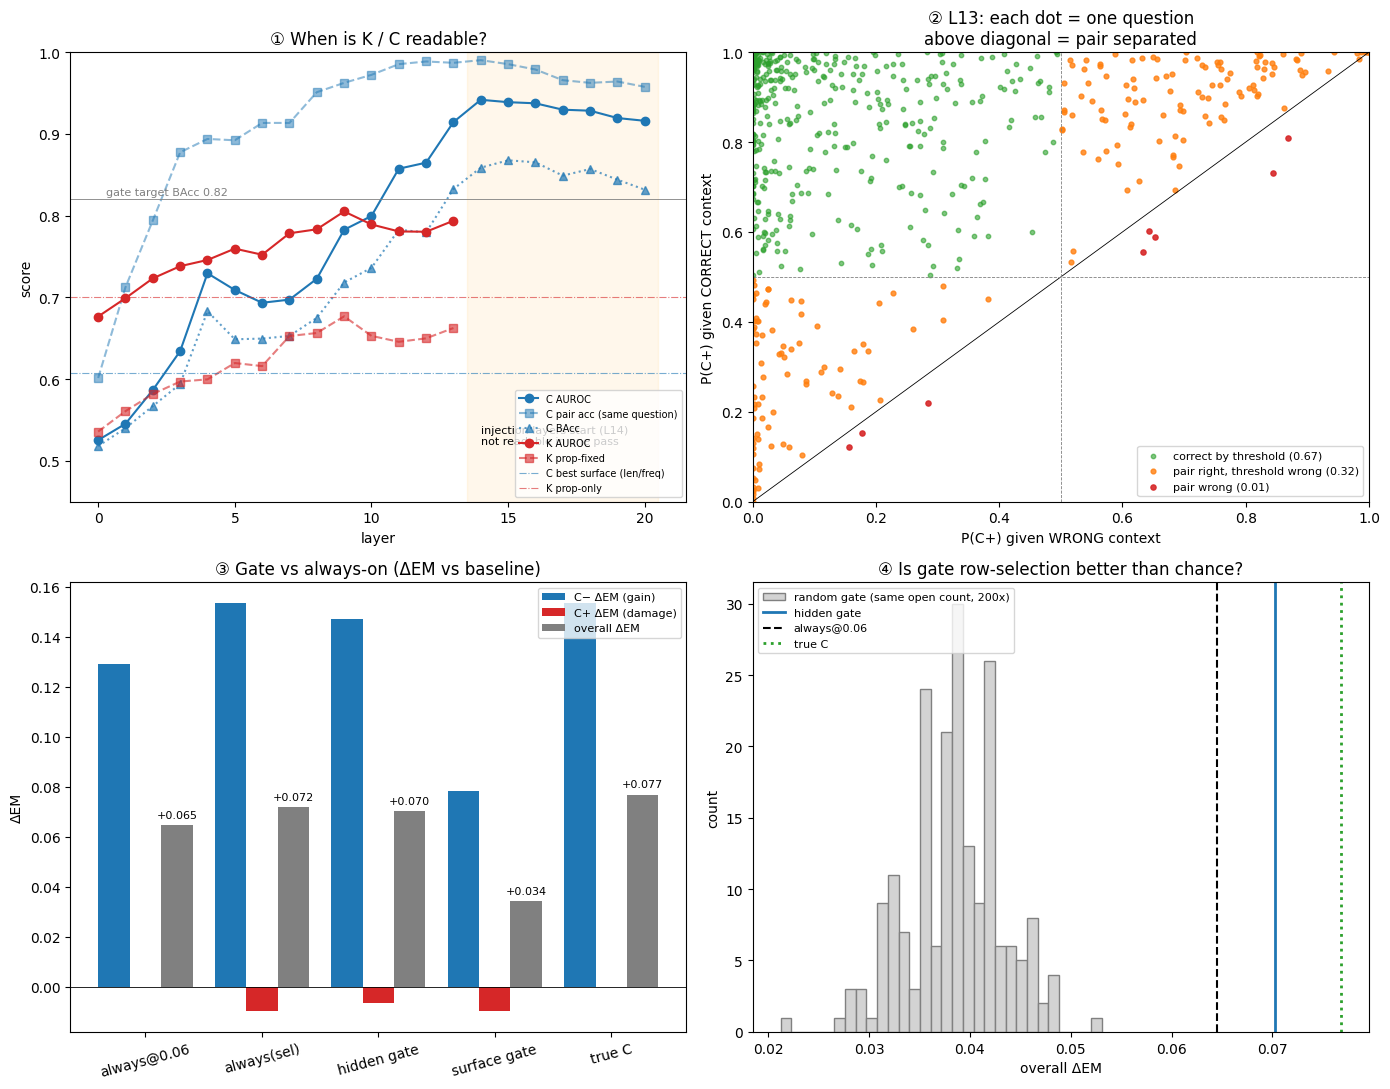

In [ ]:
## Cell 26 — A1/A2 결과 시각화 (CPU, 즉시)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(14, 11))

# ① 층별 곡선 + 표면 대조군 + 주입 시작선
a = ax[0, 0]
a.plot(A1.L, A1.C_AUROC, 'o-', c='C0', label='C AUROC')
a.plot(A1.L, A1.C_pair, 's--', c='C0', alpha=.5, label='C pair acc (same question)')
a.plot(A1.L, A1.C_BAcc, '^:', c='C0', alpha=.7, label='C BAcc')
a.plot(A1.L, A1.K_AUROC, 'o-', c='C3', label='K AUROC')
a.plot(A1.L, A1.K_propfixed, 's--', c='C3', alpha=.6, label='K prop-fixed')
a.axhline(descC(SURF[('C', 'len_freq')][0])['AUROC'], c='C0', lw=.8, ls='-.', alpha=.6,
          label='C best surface (len/freq)')
a.axhline(descK(SURF[('K', 'prop')][0])['AUROC'], c='C3', lw=.8, ls='-.', alpha=.6,
          label='K prop-only')
a.axhline(.82, c='gray', lw=.6)
a.text(0.3, .825, 'gate target BAcc 0.82', fontsize=8, color='gray')
a.axvspan(13.5, 20.5, color='orange', alpha=.08)
a.text(14, .52, 'injection layers start (L14)\nnot readable in one pass', fontsize=8)
a.set(xlabel='layer', ylabel='score', title='① When is K / C readable?', ylim=(.45, 1.0))
a.legend(fontsize=7, loc='lower right')

# ② 짝 산점도: 질문별 기준점 문제
a = ax[0, 1]
s13 = pick_lambda(*PROBE[('C', 13)], yC)
x, y = s13[cm_idx], s13[cp_idx]
ok_pair = y > x
ok_abs = (y >= .5) & (x < .5)
a.scatter(x[ok_abs], y[ok_abs], s=10, c='C2', alpha=.6, label=f'correct by threshold ({ok_abs.mean():.2f})')
a.scatter(x[ok_pair & ~ok_abs], y[ok_pair & ~ok_abs], s=12, c='C1', alpha=.8,
          label=f'pair right, threshold wrong ({(ok_pair & ~ok_abs).mean():.2f})')
a.scatter(x[~ok_pair], y[~ok_pair], s=14, c='C3', alpha=.9, label=f'pair wrong ({(~ok_pair).mean():.2f})')
a.plot([0, 1], [0, 1], 'k', lw=.6)
a.axvline(.5, c='gray', lw=.6, ls='--')
a.axhline(.5, c='gray', lw=.6, ls='--')
a.set(xlabel='P(C+) given WRONG context', ylabel='P(C+) given CORRECT context',
      title='② L13: each dot = one question\nabove diagonal = pair separated', xlim=(0, 1), ylim=(0, 1))
a.legend(fontsize=8, loc='lower right')

# ③ 게이트 비교: C− 이득 vs C+ 손상
a = ax[1, 0]
arms = [('always@0.06', em_of(0.06)), ('always(sel)', AO_sel), ('hidden gate', G_hid),
        ('surface gate', G_srf), ('true C', TRUE_C)]
xs = np.arange(len(arms))
cm_v = [(v - b0)[isCm].mean() for _, v in arms]
cp_v = [(v - b0)[~isCm].mean() for _, v in arms]
all_v = [(v - b0).mean() for _, v in arms]
a.bar(xs - .27, cm_v, .27, label='C− ΔEM (gain)', color='C0')
a.bar(xs, cp_v, .27, label='C+ ΔEM (damage)', color='C3')
a.bar(xs + .27, all_v, .27, label='overall ΔEM', color='gray')
for i, v in enumerate(all_v):
    a.text(i + .27, v + .003, f'{v:+.3f}', ha='center', fontsize=8)
a.axhline(0, c='k', lw=.6)
a.set_xticks(xs, [n for n, _ in arms], rotation=15)
a.set(title='③ Gate vs always-on (ΔEM vs baseline)', ylabel='ΔEM')
a.legend(fontsize=8)

# ④ random 게이트 분포
a = ax[1, 1]
a.hist(rand_all - b0.mean(), bins=30, color='lightgray', edgecolor='gray',
       label='random gate (same open count, 200x)')
a.axvline(G_hid.mean() - b0.mean(), c='C0', lw=2, label='hidden gate')
a.axvline(em_of(0.06).mean() - b0.mean(), c='k', ls='--', label='always@0.06')
a.axvline(TRUE_C.mean() - b0.mean(), c='C2', ls=':', lw=2, label='true C')
a.set(title='④ Is gate row-selection better than chance?', xlabel='overall ΔEM', ylabel='count')
a.legend(fontsize=8)

plt.tight_layout()
plt.savefig(ROOT / 'gen' / 'A1_A2_summary.png', dpi=150)
plt.show()

In [ ]:
import datetime as dt

In [ ]:
## Cell 27 — 사후 가설 사전등록 (Q-first 결과를 보기 전에 저장)
PREREG_QF = {
 'date': dt.datetime.now(dt.timezone(dt.timedelta(hours=9))).isoformat(),
 'type': 'post-hoc hypothesis (A 결과의 짝 정확도 0.987 vs BAcc 0.833 관찰 후 설정). 확인적 결과 아님',
 'base_prereg_md5': 'f114ed6e5119e49a0ec4656c859ac1bb',
 'hypothesis': 'Q-first에서 diff = h_last − h_q 특징이 질문별 기준점을 제거해 C 게이트 오판을 줄인다',
 'prompt': "Q-first: 'Question: {q}\\nContext: {c}\\nAnswer:' + p8s-v2 SYSTEM_PROMPT",
 'bank': 'Q-first base + retain ρ ∈ {0.04, 0.06, 0.08, 0.10, 0.12}, w는 Q-first 기준선 행동으로 fold별 재추정',
 'features': {'last': 'h_last(L)', 'diff': 'h_last(L) − h_q(L)', 'q': 'h_q(L) — C 음성 대조군'},
 'layers': 'L0–13',
 'selection': 'prereg_A와 동일 (outer-train 안에서 층·λ·ρ·τ, C+ 하한 > −0.02)',
 'primary': 'Q-first diff 게이트 − Q-first always@0.06, 전체 ΔEM paired CI 하한 > 0',
 'secondary': ['diff 게이트 − last 게이트 (같은 Q-first bank, 기준점 보정 효과만 분리)',
               'diff 게이트 − always(sel)', 'diff 게이트 − 참 C', 'diff 게이트 − random'],
 'checks': ['h_q의 C+/C− 짝 relRMS < 0.03', 'q 특징의 C AUROC ≈ 0.5', '부호: +ρ에서 C− follows_ctx 감소'],
 'descriptive_only': 'p8s-v2 결과와의 비교 (프롬프트가 달라 bank가 다름)',
}
json.dump(PREREG_QF, open(ROOT / 'env' / 'prereg_QF.json', 'w'), ensure_ascii=False, indent=1)
print('저장 md5:', md5(open(ROOT / 'env' / 'prereg_QF.json', 'rb').read()))

저장 md5: 6c314336a233725dbc31e53350aa205f


In [ ]:
## Cell 28 — Q-first 프롬프트·질문끝 위치 + 기준선 + hidden 캡처 (h_last, h_q, L0–18)
def render(q, c, qfirst):
    user = (f'Question: {q}\nContext: {c}\nAnswer:' if qfirst
            else f'Context: {c}\nQuestion: {q}\nAnswer:')
    text = TOK.apply_chat_template([{'role': 'system', 'content': PP.SYSTEM_PROMPT},
                                    {'role': 'user', 'content': user}],
                                   tokenize=False, add_generation_prompt=True)
    return text, user

# 렌더러 검증: 같은 함수로 p8s-v2를 만들면 기존 프롬프트와 같아야 함
n_ok = sum(render(r.question, r.ctx_text, False)[0] == p for r, p in zip(m.itertuples(), m.prompt))
print('p8s-v2 렌더러 일치', n_ok, '/ 1224  (기대 1224)')
assert n_ok == len(m)

PQ, QIDX, NQ = [], [], []
for r in m.itertuples():
    text, user = render(r.question, r.ctx_text, True)
    base = text.rfind(user)
    qs = base + len('Question: ')
    qe = qs + len(r.question)
    cs = qe + len('\nContext: ')
    enc = TOK(text, add_special_tokens=False, return_offsets_mapping=True)
    off = enc['offset_mapping']
    qi = [i for i, (s, e) in enumerate(off) if e > qs and s < qe and e > s]
    assert qi and off[qi[-1]][1] <= cs, '질문 위치가 문맥으로 넘어감'
    PQ.append(text); QIDX.append(qi[-1]); NQ.append(len(enc['input_ids']))
m['prompt_qf'], m['qidx_qf'], m['n_tok_qf'] = PQ, QIDX, NQ
FOLD_ROWS_QF = {k: m[m.fold == k].sort_values(['n_tok_qf', 'rid'], kind='stable').rid.values
                for k in range(5)}

# 생성 함수: 프롬프트 배열을 인자로 받게 일반화
@torch.no_grad()
def gen_rows_p(rids, prompts, gate_of=None):
    out = {}
    for s in range(0, len(rids), BS):
        b = rids[s:s + BS]
        enc = TOK(prompts[b].tolist(), return_tensors='pt', padding=True,
                  add_special_tokens=False).to(MODEL.device)
        ST.mask = enc.attention_mask
        ST.gate = torch.tensor([1.0 if gate_of is None else float(gate_of[int(r)]) for r in b],
                               device=MODEL.device)
        g = MODEL.generate(**enc, max_new_tokens=PP.MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=TOK.pad_token_id, eos_token_id=EOS_IDS)[:, enc.input_ids.shape[1]:]
        for r, row in zip(b, g.tolist()):
            stop = next((i for i, t in enumerate(row) if t in EOS_IDS), None)
            n = stop if stop is not None else len(row)
            out[int(r)] = (TOK.decode(row[:n], **DECODE_KW), n, json.dumps(row[:n]))
    return out

def run_qf(tag, rho, Wd=None, Md=None):
    f = ROOT / 'gen' / f'QF_{tag}.parquet'
    if f.exists():
        return pd.read_parquet(f)
    t0, rec = time.time(), []
    for k in range(5):
        if rho:
            ST.d = {L: torch.as_tensor(rho * Md[k][L] * Wd[k][L], device=MODEL.device, dtype=MODEL.dtype)
                    for L in LAY}
        else:
            ST.d = None
        rec += [dict(rid=r, raw=x, n_tok=n, ids=i)
                for r, (x, n, i) in gen_rows_p(FOLD_ROWS_QF[k], m.prompt_qf.values).items()]
    ST.d = None
    df = score(pd.DataFrame(rec))
    df.to_parquet(f, index=False)
    print(f'QF_{tag}: {time.time()-t0:.0f}s')
    return df

BASE_QF = run_qf('base', 0)
d_pr = BASE_QF.em.values - b0
print('Q-first 기준선 EM', BASE_QF.em.mean().round(4), '| C−', BASE_QF.em[isCm].mean().round(4),
      '| C+', BASE_QF.em[~isCm].mean().round(4))
paired(BASE_QF.em.values, b0, '프롬프트 효과 (Q-first − p8s-v2)')

# hidden 캡처: 마지막 토큰 + 질문끝 토큰, L0–18
HQP = ROOT / 'hidden' / 'qf_h_last_q_L0-18.npz'
if HQP.exists():
    z = np.load(HQP); HQ_last, HQ_q = z['last'], z['q']
else:
    NL = 19
    HQ_last = np.zeros((len(m), NL, 4096), np.float16)
    HQ_q = np.zeros((len(m), NL, 4096), np.float16)
    cap, QPOS = {}, {}
    def mk(L):
        def f(mod, a, out):
            h = out[0] if isinstance(out, (tuple, list)) else out
            cap[L] = (h[:, -1, :].float().cpu(),
                      h[torch.arange(h.shape[0], device=h.device), QPOS['t']].float().cpu())
        return f
    hooks = [MODEL.model.layers[L].register_forward_hook(mk(L)) for L in range(NL)]
    order = m.sort_values(['n_tok_qf', 'rid'], kind='stable').rid.values
    t0 = time.time()
    with torch.no_grad():
        for s in range(0, len(order), BS):
            b = order[s:s + BS]
            enc = TOK(m.prompt_qf.values[b].tolist(), return_tensors='pt', padding=True,
                      add_special_tokens=False).to(MODEL.device)
            T = enc.input_ids.shape[1]
            QPOS['t'] = torch.tensor([T - m.n_tok_qf.values[r] + m.qidx_qf.values[r] for r in b],
                                     device=MODEL.device)
            MODEL.model(**enc, use_cache=False)
            for L in range(NL):
                HQ_last[b, L] = cap[L][0].numpy().astype(np.float16)
                HQ_q[b, L] = cap[L][1].numpy().astype(np.float16)
    for h in hooks:
        h.remove()
    np.savez(HQP, last=HQ_last, q=HQ_q)
    print(f'캡처 {time.time()-t0:.0f}s')

# 정렬 검증: h_q는 문맥을 못 보므로 같은 질문의 C+/C−에서 같아야 함
rel = [np.linalg.norm(HQ_q[cp_idx, L].astype(np.float32) - HQ_q[cm_idx, L].astype(np.float32), axis=1).mean()
       / np.linalg.norm(HQ_q[cp_idx, L].astype(np.float32), axis=1).mean() for L in (0, 7, 13)]
print('h_q 짝 relRMS (L0/L7/L13):', np.round(rel, 4), ' (기대 < 0.03)')

p8s-v2 렌더러 일치 1224 / 1224  (기대 1224)
QF_base: 47s
Q-first 기준선 EM 0.5719 | C− 0.3513 | C+ 0.7925
프롬프트 효과 (Q-first − p8s-v2): +0.0408 [+0.0204, +0.0621]  Net 50행 (+103 / −53)
캡처 24s
h_q 짝 relRMS (L0/L7/L13): [0.0028 0.0078 0.0092]  (기대 < 0.03)


In [ ]:
def pbd(X, pos, neg, min_n=3):
    ds = []
    for q in np.unique(PR[pos | neg]):
        i = PR == q
        if (pos & i).sum() >= min_n and (neg & i).sum() >= min_n:
            ds.append(X[pos & i].mean(0) - X[neg & i].mean(0))
    d = np.mean(ds, 0)
    return d / np.linalg.norm(d), len(ds)

In [ ]:
## Cell 29 — Q-first w 재추정 + 부호 검증 + action bank (ρ 0.04~0.12)
p_ = np.array([PP.norm(x) for x in BASE_QF.pred])
s_ = m.answer_surface.fillna('').map(PP.norm).values
c_ = m.cb_greedy_v3.fillna('').map(PP.norm).values
acc_q = ((s_ != '') & (p_ == s_))
ret_q = ((c_ != '') & (c_ != s_) & (p_ == c_))

W_QF, MED_QF, info = {}, {}, []
for k in range(5):
    tr = FOLD != k
    ret, acc = tr & isCm & ret_q, tr & isCm & acc_q
    W_QF[k], MED_QF[k] = {}, {}
    for L in LAY:
        X = HQ_last[:, L].astype(np.float32)
        W_QF[k][L], npr = pbd(X, ret, acc) if 'pbd' in globals() else (None, None)
        MED_QF[k][L] = float(np.median(np.linalg.norm(X[tr], axis=1)))
    info.append(dict(fold=k, n_ret=int(ret.sum()), n_acc=int(acc.sum()), props=npr))
print(pd.DataFrame(info))
print('cos(w_QF, w_v3) L16 fold0:', round(float(W_QF[0][16] @ W3[0][16]), 3))
np.savez(ROOT / 'hidden' / 'w_qf.npz', **{f'w_f{k}_L{L}': W_QF[k][L] for k in W_QF for L in LAY},
         **{f'med_f{k}_L{L}': MED_QF[k][L] for k in MED_QF for L in LAY})

RHO_QF = [0.04, 0.06, 0.08, 0.10, 0.12]
RES_QF = {0.0: BASE_QF}
for rho in RHO_QF:
    RES_QF[rho] = run_qf(f'r{rho:+.2f}', rho, W_QF, MED_QF)

print('\n부호 검증: C− follows_ctx  base', round(BASE_QF.follows_ctx[isCm].mean(), 3),
      '→ ρ0.06', round(RES_QF[0.06].follows_ctx[isCm].mean(), 3), '(감소해야 정상)')
rows = []
for rho in RHO_QF:
    d = RES_QF[rho].em.values - BASE_QF.em.values
    r = {'rho': rho}
    for lab, sel in [('C−', isCm), ('C+', ~isCm)]:
        lo, hi = ci_d(d, sel)
        r[lab] = f'{d[sel].mean():+.4f} [{lo:+.3f}, {hi:+.3f}]'
    r['hit'] = RES_QF[rho].hit_limit.mean()
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

   fold  n_ret  n_acc  props
0     0    163    179     12
1     1    168    170     12
2     2    162    182     12
3     3    164    182     11
4     4    171    171     11
cos(w_QF, w_v3) L16 fold0: 0.742
QF_r+0.04: 58s
QF_r+0.06: 56s
QF_r+0.08: 59s
QF_r+0.10: 60s
QF_r+0.12: 51s

부호 검증: C− follows_ctx  base 0.361 → ρ0.06 0.168 (감소해야 정상)
 rho                       C−                       C+      hit
0.04 +0.0915 [+0.067, +0.118] -0.0147 [-0.036, +0.003] 0.000817
0.06 +0.1225 [+0.092, +0.154] -0.0343 [-0.059, -0.010] 0.000817
0.08 +0.1438 [+0.109, +0.176] -0.0654 [-0.095, -0.038] 0.000817
0.10 +0.1454 [+0.109, +0.181] -0.1046 [-0.137, -0.072] 0.000817
0.12 +0.1373 [+0.100, +0.175] -0.1797 [-0.217, -0.142] 0.000000


In [ ]:
## Cell 30 — Q-first probe (배치 적합): 특징 last / diff / q, L0–13
MASKS, TAGS = [], []
for i in range(5):
    MASKS.append((FOLD != i, FOLD == i)); TAGS.append(('outer', i, None))
    for j in range(5):
        if j != i:
            MASKS.append(((FOLD != i) & (FOLD != j), FOLD == j)); TAGS.append(('inner', i, j))

def probe_batched(Xnp, y, steps=400, lr=0.05):
    """마스크 25 × λ 4 = 100개 로지스틱을 한 번에 학습. 표준화는 각 train 마스크 통계로만"""
    X = torch.as_tensor(Xnp, device=dev, dtype=torch.float32)
    Y = torch.as_tensor(y, device=dev)
    nC = len(MASKS) * len(LAMS)
    TRW = torch.zeros(nC, len(m), device=dev)
    LAM = torch.zeros(nC, device=dev)
    MU = torch.zeros(nC, X.shape[1], device=dev)
    SD = torch.zeros_like(MU)
    c = 0
    for tr, te in MASKS:
        t = torch.as_tensor(tr, device=dev)
        mu, sd = X[t].mean(0), X[t].std(0) + 1e-6
        pw = (1 - Y[t].mean()) / Y[t].mean()
        wr = torch.where(Y > 0, pw, torch.ones_like(Y)) * t.float()
        wr = wr / wr.sum()
        for lam in LAMS:
            TRW[c], LAM[c], MU[c], SD[c] = wr, lam, mu, sd
            c += 1
    W = torch.zeros(nC, X.shape[1], device=dev, requires_grad=True)
    B = torch.zeros(nC, device=dev, requires_grad=True)
    opt = torch.optim.Adam([W, B], lr=lr)
    Yx = Y[:, None].expand(len(m), nC)
    for _ in range(steps):
        opt.zero_grad()
        V = W / SD
        Zl = X @ V.T - (MU * V).sum(1) + B
        bce = F.binary_cross_entropy_with_logits(Zl, Yx, reduction='none')
        loss = ((bce * TRW.T).sum(0) + LAM * (W * W).sum(1)).sum()
        loss.backward()
        opt.step()
    with torch.no_grad():
        V = W / SD
        P = torch.sigmoid(X @ V.T - (MU * V).sum(1) + B).cpu().numpy()
    outer = {l: np.zeros(len(m), np.float32) for l in LAMS}
    inner = {i: {l: np.full(len(m), np.nan, np.float32) for l in LAMS} for i in range(5)}
    c = 0
    for (tr, te), (kind, i, j) in zip(MASKS, TAGS):
        for lam in LAMS:
            (outer[lam] if kind == 'outer' else inner[i][lam])[te] = P[te, c]
            c += 1
    return outer, inner

def descC2(s):
    pr = np.where(s[cp_idx] == s[cm_idx], .5, (s[cp_idx] > s[cm_idx]).astype(float))   # 동점은 0.5
    return dict(AUROC=roc_auc_score(yC, s), BAcc=balanced_accuracy_score(yC, s >= .5), pair=pr.mean())

# 교정 검사: 같은 방법으로 p8s-v2 L13 → Cell 24(LBFGS)의 AUROC 0.914와 비슷해야 함
t0 = time.time()
chk = descC2(pick_lambda(*probe_batched(H[:, 13].astype(np.float32), yC), yC))
print(f'교정 검사 p8s-v2 L13: {chk}  ({time.time()-t0:.0f}s, 기대 AUROC ≈ 0.91)')

PROBE_QF, rows = {}, []
for L in range(14):
    feats = {'last': HQ_last[:, L].astype(np.float32),
             'diff': HQ_last[:, L].astype(np.float32) - HQ_q[:, L].astype(np.float32),
             'q':    HQ_q[:, L].astype(np.float32)}
    r = {'L': L}
    for fn, X in feats.items():
        PROBE_QF[('C', fn, L)] = probe_batched(X, yC)
        for k, v in descC2(pick_lambda(*PROBE_QF[('C', fn, L)], yC)).items():
            r[f'{fn}_{k}'] = v
    PROBE_QF[('K', 'q', L)] = probe_batched(feats['q'], yK)      # 문맥을 보기 전 K
    r.update({f'Kq_{k}': v for k, v in descK(pick_lambda(*PROBE_QF[('K', 'q', L)], yK)).items()})
    rows.append(r)
    print(f'L{L} {time.time()-t0:.0f}s', end=' | ')
A1QF = pd.DataFrame(rows)
pickle.dump(PROBE_QF, open(ROOT / 'hidden' / 'A1_qf_probes.pkl', 'wb'))
print()
print(A1QF.round(3).to_string(index=False))

교정 검사 p8s-v2 L13: {'AUROC': np.float64(0.9030861527617582), 'BAcc': np.float64(0.8292483660130718), 'pair': np.float64(0.988562091503268)}  (1s, 기대 AUROC ≈ 0.91)
L0 3s | L1 5s | L2 8s | L3 10s | L4 13s | L5 15s | L6 17s | L7 20s | L8 22s | L9 25s | L10 27s | L11 30s | L12 32s | L13 35s | 
 L  last_AUROC  last_BAcc  last_pair  diff_AUROC  diff_BAcc  diff_pair  q_AUROC  q_BAcc  q_pair  Kq_AUROC  Kq_propfixed
 0       0.525      0.517      0.605       0.552      0.534      0.744    0.592   0.571   0.692     0.638         0.512
 1       0.553      0.543      0.731       0.579      0.551      0.851    0.587   0.565   0.787     0.679         0.543
 2       0.604      0.578      0.828       0.588      0.566      0.853    0.588   0.556   0.790     0.716         0.580
 3       0.631      0.604      0.863       0.585      0.555      0.837    0.551   0.534   0.787     0.638         0.535
 4       0.689      0.650      0.892       0.597      0.574      0.906    0.523   0.509   0.779     0.699     

In [ ]:
## Cell 31 — Q-first 게이트 선택·평가 (prereg_QF 그대로, CPU)
b0q = BASE_QF.em.values
em_qf = lambda rho: RES_QF[round(rho, 2)].em.values

def select_gate_g(cands, em_fn, base, rhos):
    out, opened, picks = base.astype(float).copy(), np.zeros(len(m), bool), []
    for i in range(5):
        tr, te = FOLD != i, FOLD == i
        best = (0.0, 'noop', None, None)
        for key, ov, iv in cands:
            p = np.nan_to_num(iv[i], nan=1.0)
            for rho in rhos:
                e = em_fn(rho)
                for tau in TAUS:
                    d = np.where(p < tau, e, base) - base
                    obj = d[tr].mean()
                    if obj <= best[0] or ci_d(d, tr & ~isCm, B=500)[0] <= -0.02:
                        continue
                    best = (obj, key, rho, tau)
        _, key, rho, tau = best
        picks.append(dict(fold=i, key=str(key), rho=rho, tau=tau, train_obj=round(best[0], 4)))
        if key != 'noop':
            ov = {k: o for k, o, _ in cands}[key]
            g = te & (ov < tau)
            opened |= g
            out[g] = em_fn(rho)[g]
    return out, opened, pd.DataFrame(picks)

def cands_of(fn):
    return [((fn, L, lam), PROBE_QF[('C', fn, L)][0][lam],
             {i: PROBE_QF[('C', fn, L)][1][i][lam] for i in range(5)})
            for L in range(14) for lam in LAMS]

G_diff, op_diff, pk_diff = select_gate_g(cands_of('diff'), em_qf, b0q, RHO_QF)
G_last, op_last, pk_last = select_gate_g(cands_of('last'), em_qf, b0q, RHO_QF)
print('[diff 게이트 선택]\n', pk_diff.to_string(index=False))
print('[last 게이트 선택]\n', pk_last.to_string(index=False))

# 비교군 (모두 Q-first bank)
AO_qf_sel = np.zeros(len(m))
for i in range(5):
    tr, te = FOLD != i, FOLD == i
    r_ = max(RHO_QF, key=lambda x: (em_qf(x)[tr] - b0q[tr]).mean())
    AO_qf_sel[te] = em_qf(r_)[te]
rho_f = {r.fold: r.rho for r in pk_diff.itertuples()}
TRUE_Cq = b0q.astype(float).copy()
for i, rho in rho_f.items():
    if rho is not None and not pd.isna(rho):
        s = (FOLD == i) & isCm
        TRUE_Cq[s] = em_qf(rho)[s]
rng = np.random.default_rng(SEED)
rand_q = []
for _ in range(200):
    v = b0q.astype(float).copy()
    for i, rho in rho_f.items():
        n = int((op_diff & (FOLD == i)).sum())
        if rho is None or pd.isna(rho) or n == 0:
            continue
        g = rng.choice(np.where(FOLD == i)[0], n, replace=False)
        v[g] = em_qf(rho)[g]
    rand_q.append(v.mean())
rand_q = np.array(rand_q)

print('\n[주 비교 (사전등록)]')
paired(G_diff, em_qf(0.06), 'diff 게이트 − QF always@0.06')
print('\n[2차 비교]')
paired(G_diff, G_last, 'diff 게이트 − last 게이트 (기준점 보정 효과)')
paired(G_diff, AO_qf_sel, 'diff 게이트 − QF always(sel)')
paired(G_diff, TRUE_Cq, 'diff 게이트 − 참 C')
paired(G_diff, b0q, 'diff 게이트 − QF 기준선 (개입 없음)')
print(f'diff 게이트 − random 평균 {G_diff.mean() - rand_q.mean():+.4f} | random ≥ 게이트 {(rand_q >= G_diff.mean()).mean():.3f}')

def cellrep2(v, base, name):
    d = v - base
    r = {'arm': name, 'EM': v.mean(), 'ΔEM': d.mean(), 'C−': d[isCm].mean(), 'C+': d[~isCm].mean()}
    for c in ['K+C+', 'K+C−', 'K−C+', 'K−C−']:
        s = (m.cell == c).values
        r[c] = f'{int((d[s] == 1).sum())}/{int((d[s] == -1).sum())}'
    return r

print(f'\n개방률 diff {op_diff.mean():.3f} (C− {op_diff[isCm].mean():.3f} / C+ {op_diff[~isCm].mean():.3f})'
      f' | last {op_last.mean():.3f} (C− {op_last[isCm].mean():.3f} / C+ {op_last[~isCm].mean():.3f})')
print(pd.DataFrame([cellrep2(em_qf(0.06), b0q, 'QF always@0.06'), cellrep2(AO_qf_sel, b0q, 'QF always(sel)'),
                    cellrep2(G_diff, b0q, 'QF diff gate'), cellrep2(G_last, b0q, 'QF last gate'),
                    cellrep2(TRUE_Cq, b0q, 'QF true C')]).round(4).to_string(index=False))

# 서술용: 프롬프트를 넘나드는 절대 EM (bank가 달라 검정하지 않음)
print('\n[서술용 절대 EM]')
for n_, v in [('p8s-v2 base', b0), ('p8s-v2 always@0.06', em_of(0.06)), ('p8s-v2 hidden gate', G_hid),
              ('QF base', b0q), ('QF always@0.06', em_qf(0.06)), ('QF diff gate', G_diff), ('QF last gate', G_last)]:
    print(f'  {n_:22s} EM {v.mean():.4f} | C− {v[isCm].mean():.4f} | C+ {v[~isCm].mean():.4f}')

json.dump({'picks_diff': pk_diff.to_dict('records'), 'picks_last': pk_last.to_dict('records')},
          open(ROOT / 'gen' / 'QF_gate_results.json', 'w'), ensure_ascii=False, indent=1, default=str)

[diff 게이트 선택]
  fold                 key  rho  tau  train_obj
    0  ('diff', 13, 0.01) 0.06  0.3     0.0449
    1 ('diff', 13, 0.001) 0.06  0.4     0.0481
    2 ('diff', 13, 0.001) 0.06  0.3     0.0510
    3 ('diff', 13, 0.001) 0.06  0.7     0.0490
    4  ('diff', 13, 0.01) 0.04  0.5     0.0317
[last 게이트 선택]
  fold                  key  rho  tau  train_obj
    0   ('last', 13, 0.01) 0.06  0.3     0.0510
    1    ('last', 13, 0.1) 0.06  0.7     0.0573
    2    ('last', 13, 0.1) 0.06  0.3     0.0531
    3     ('last', 4, 0.1) 0.06  0.6     0.0449
    4 ('last', 13, 0.0001) 0.06  0.6     0.0481

[주 비교 (사전등록)]
diff 게이트 − QF always@0.06: +0.0008 [-0.0123, +0.0131]  Net 1행 (+30 / −29)

[2차 비교]
diff 게이트 − last 게이트 (기준점 보정 효과): +0.0057 [-0.0025, +0.0147]  Net 7행 (+18 / −11)
diff 게이트 − QF always(sel): +0.0008 [-0.0123, +0.0131]  Net 1행 (+30 / −29)
diff 게이트 − 참 C: -0.0131 [-0.0212, -0.0049]  Net -16행 (+6 / −22)
diff 게이트 − QF 기준선 (개입 없음): +0.0449 [+0.0294, +0.0605]  Net 55행 (+77 / −22)
diff 게이트 

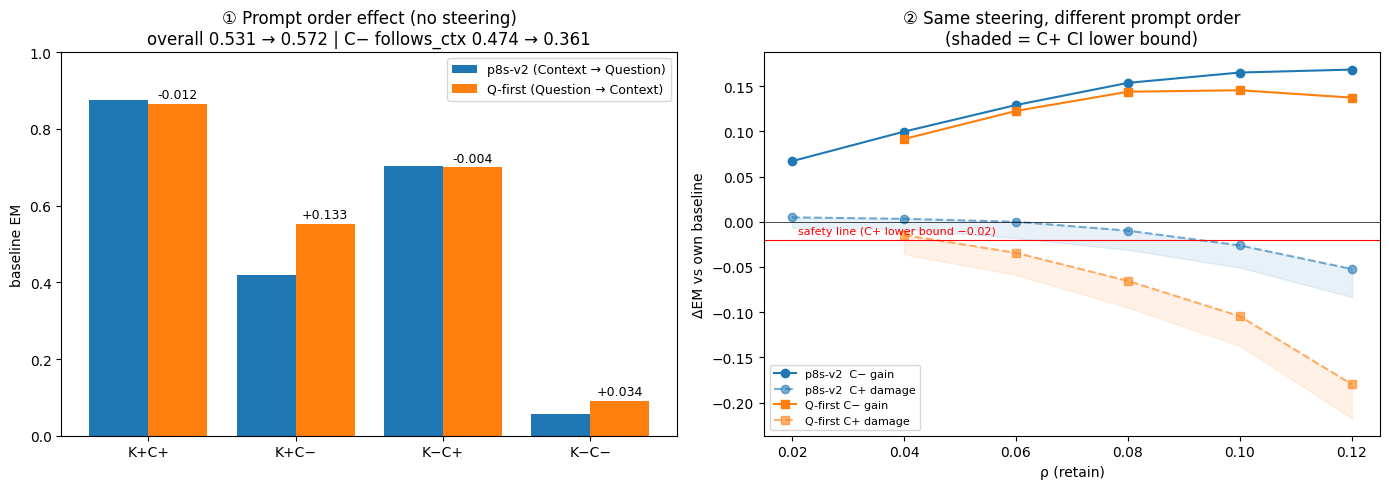

In [ ]:
## Cell 32 — 프롬프트 순서 효과 + 강도 곡선 비교 (CPU, 즉시)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
CELLS = ['K+C+', 'K+C−', 'K−C+', 'K−C−']

# ① 4셀 기준선 EM + C− follows_ctx
a = ax[0]
xs = np.arange(len(CELLS))
e_v2 = [b0[(m.cell == c).values].mean() for c in CELLS]
e_qf = [b0q[(m.cell == c).values].mean() for c in CELLS]
a.bar(xs - .2, e_v2, .4, label='p8s-v2 (Context → Question)', color='C0')
a.bar(xs + .2, e_qf, .4, label='Q-first (Question → Context)', color='C1')
for i in range(len(CELLS)):
    a.text(i + .2, e_qf[i] + .015, f'{e_qf[i] - e_v2[i]:+.3f}', ha='center', fontsize=9)
f_v2 = BASE.follows_ctx[isCm].mean()
f_qf = BASE_QF.follows_ctx[isCm].mean()
a.set_xticks(xs, CELLS)
a.set(ylabel='baseline EM', ylim=(0, 1),
      title=f'① Prompt order effect (no steering)\n'
            f'overall {b0.mean():.3f} → {b0q.mean():.3f} | C− follows_ctx {f_v2:.3f} → {f_qf:.3f}')
a.legend(fontsize=9)

# ② ρ별 C− 이득 / C+ 손상
a = ax[1]
rv2 = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
rqf = RHO_QF
dv2 = {r: em_of(r) - b0 for r in rv2}
dqf = {r: em_qf(r) - b0q for r in rqf}
a.plot(rv2, [dv2[r][isCm].mean() for r in rv2], 'o-', c='C0', label='p8s-v2  C− gain')
a.plot(rv2, [dv2[r][~isCm].mean() for r in rv2], 'o--', c='C0', alpha=.6, label='p8s-v2  C+ damage')
a.plot(rqf, [dqf[r][isCm].mean() for r in rqf], 's-', c='C1', label='Q-first C− gain')
a.plot(rqf, [dqf[r][~isCm].mean() for r in rqf], 's--', c='C1', alpha=.6, label='Q-first C+ damage')
lo_v2 = [ci_d(dv2[r], ~isCm)[0] for r in rv2]
lo_qf = [ci_d(dqf[r], ~isCm)[0] for r in rqf]
a.fill_between(rv2, lo_v2, [dv2[r][~isCm].mean() for r in rv2], color='C0', alpha=.1)
a.fill_between(rqf, lo_qf, [dqf[r][~isCm].mean() for r in rqf], color='C1', alpha=.1)
a.axhline(-.02, c='r', lw=.8)
a.text(.021, -.013, 'safety line (C+ lower bound −0.02)', color='r', fontsize=8)
a.axhline(0, c='k', lw=.5)
a.set(xlabel='ρ (retain)', ylabel='ΔEM vs own baseline',
      title='② Same steering, different prompt order\n(shaded = C+ CI lower bound)')
a.legend(fontsize=8, loc='lower left')

plt.tight_layout()
plt.savefig(ROOT / 'gen' / 'QF_prompt_strength.png', dpi=150)
plt.show()

In [ ]:
## Cell 33 — 패딩 흔적 점검: bs1 재캡처 (Q-first, h_last·h_q, L0–13) → probe 재실행
NL2 = 14
H1_last = np.zeros((len(m), NL2, 4096), np.float16)
H1_q = np.zeros((len(m), NL2, 4096), np.float16)
cap = {}
def mk1(L):
    def f(mod, a, out):
        h = out[0] if isinstance(out, (tuple, list)) else out
        cap[L] = (h[0, -1, :].float().cpu(), h[0, QP1['t'], :].float().cpu())
    return f
QP1 = {}
hooks = [MODEL.model.layers[L].register_forward_hook(mk1(L)) for L in range(NL2)]
t0 = time.time()
with torch.no_grad():
    for r in range(len(m)):
        enc = TOK(m.prompt_qf.values[r], return_tensors='pt', add_special_tokens=False).to(MODEL.device)
        QP1['t'] = int(m.qidx_qf.values[r])
        MODEL.model(**enc, use_cache=False)
        for L in range(NL2):
            H1_last[r, L] = cap[L][0].numpy().astype(np.float16)
            H1_q[r, L] = cap[L][1].numpy().astype(np.float16)
for h in hooks:
    h.remove()
np.savez(ROOT / 'hidden' / 'qf_bs1_L0-13.npz', last=H1_last, q=H1_q)
print(f'bs1 캡처 {time.time()-t0:.0f}s')

# (a) bs1에서 h_q 짝 차이: 0에 가까워야 함 (문맥을 못 보므로 완전히 같은 입력)
rel1 = [np.linalg.norm(H1_q[cp_idx, L].astype(np.float32) - H1_q[cm_idx, L].astype(np.float32), axis=1).mean()
        / np.linalg.norm(H1_q[cp_idx, L].astype(np.float32), axis=1).mean() for L in (0, 7, 13)]
print('bs1 h_q 짝 relRMS (L0/L7/L13):', np.round(rel1, 5), ' (bs16 캡처: 0.0028 / 0.0078 / 0.0092)')

# (b) 배치 캡처 vs bs1 차이 크기
drift = [np.linalg.norm(HQ_last[:, L].astype(np.float32) - H1_last[:, L].astype(np.float32), axis=1).mean()
         / np.linalg.norm(H1_last[:, L].astype(np.float32), axis=1).mean() for L in (0, 7, 13)]
print('h_last bs16 vs bs1 relRMS (L0/L7/L13):', np.round(drift, 4))

# (c) probe 재실행: bs1 hidden으로 q / last / diff
rows1 = []
for L in range(NL2):
    r = {'L': L}
    for fn, X in {'q': H1_q[:, L], 'last': H1_last[:, L],
                  'diff': H1_last[:, L].astype(np.float32) - H1_q[:, L].astype(np.float32)}.items():
        s = pick_lambda(*probe_batched(X.astype(np.float32), yC), yC)
        for k, v in descC2(s).items():
            r[f'{fn}_{k}'] = v
    s = pick_lambda(*probe_batched(H1_q[:, L].astype(np.float32), yK), yK)
    r.update({f'Kq_{k}': v for k, v in descK(s).items()})
    rows1.append(r)
A1QF1 = pd.DataFrame(rows1)
print(A1QF1.round(3).to_string(index=False))
print('\nbs16 대비 변화 (L13):',
      {c: round(A1QF1.loc[13, c] - A1QF.loc[13, c], 3) for c in ['q_pair', 'last_AUROC', 'last_BAcc', 'diff_BAcc', 'Kq_propfixed']})

bs1 캡처 60s
bs1 h_q 짝 relRMS (L0/L7/L13): [0.00026 0.00058 0.0007 ]  (bs16 캡처: 0.0028 / 0.0078 / 0.0092)
h_last bs16 vs bs1 relRMS (L0/L7/L13): [0.0048 0.0138 0.017 ]
 L  q_AUROC  q_BAcc  q_pair  last_AUROC  last_BAcc  last_pair  diff_AUROC  diff_BAcc  diff_pair  Kq_AUROC  Kq_propfixed
 0    0.500   0.498   0.507       0.522      0.508      0.583       0.520      0.514      0.596     0.621         0.494
 1    0.501   0.500   0.507       0.538      0.527      0.669       0.531      0.520      0.690     0.677         0.541
 2    0.500   0.499   0.507       0.541      0.525      0.686       0.537      0.519      0.726     0.707         0.568
 3    0.500   0.500   0.509       0.545      0.525      0.717       0.535      0.530      0.754     0.650         0.527
 4    0.500   0.500   0.502       0.572      0.547      0.823       0.543      0.529      0.809     0.684         0.549
 5    0.500   0.500   0.509       0.578      0.556      0.802       0.548      0.538      0.816     0.724         

In [ ]:
## Cell 34 — p8s-v2 bs1 재캡처 (last, L0–20) + w 영향 점검 + A1 probe 재실행
NL3 = 21
H1 = np.zeros((len(m), NL3, 4096), np.float16)
cap = {}
def mk2(L):
    def f(mod, a, out):
        h = out[0] if isinstance(out, (tuple, list)) else out
        cap[L] = h[0, -1, :].float().cpu()
    return f
hooks = [MODEL.model.layers[L].register_forward_hook(mk2(L)) for L in range(NL3)]
t0 = time.time()
with torch.no_grad():
    for r in range(len(m)):
        enc = TOK(m.prompt.values[r], return_tensors='pt', add_special_tokens=False).to(MODEL.device)
        MODEL.model(**enc, use_cache=False)
        for L in range(NL3):
            H1[r, L] = cap[L].numpy().astype(np.float16)
for h in hooks:
    h.remove()
np.save(ROOT / 'hidden' / 'p8sv2_bs1_L0-20.npy', H1)
print(f'bs1 캡처 {time.time()-t0:.0f}s')

# (a) w 영향: bs1 hidden으로 같은 레시피 → 기존 w_v3와 cos
if 'pbd' not in globals():
    def pbd(X, pos, neg, min_n=3):
        ds = []
        for q in np.unique(PR[pos | neg]):
            i = PR == q
            if (pos & i).sum() >= min_n and (neg & i).sum() >= min_n:
                ds.append(X[pos & i].mean(0) - X[neg & i].mean(0))
        d = np.mean(ds, 0)
        return d / np.linalg.norm(d), len(ds)
grp = pd.read_parquet(ROOT / 'hidden' / 'w_groups_v4.parquet')
acc1, ret1 = grp.acc_x.values == 1, grp.ret_x.values == 1
cosw = [[float(pbd(H1[:, L].astype(np.float32), (FOLD != k) & isCm & ret1, (FOLD != k) & isCm & acc1)[0] @ W3[k][L])
         for L in LAY] for k in range(5)]
print('cos(w_bs1, w_v3)  fold × L14–18:\n', np.round(cosw, 4))

# (b) A1 재실행 (배치 적합)
PROBE1, rows = {}, []
t0 = time.time()
for L in range(NL3):
    PROBE1[('C', L)] = probe_batched(H1[:, L].astype(np.float32), yC)
    r = {'L': L, **{f'C_{k}': v for k, v in descC2(pick_lambda(*PROBE1[('C', L)], yC)).items()}}
    if L <= 13:
        PROBE1[('K', L)] = probe_batched(H1[:, L].astype(np.float32), yK)
        r.update({f'K_{k}': v for k, v in descK(pick_lambda(*PROBE1[('K', L)], yK)).items()})
    rows.append(r)
A1b = pd.DataFrame(rows)
pickle.dump(PROBE1, open(ROOT / 'hidden' / 'A1_bs1_probes.pkl', 'wb'))
print(f'probe {time.time()-t0:.0f}s')
cmp = A1b[['L', 'C_AUROC', 'C_BAcc', 'C_pair', 'K_AUROC', 'K_propfixed']].copy()
cmp['ΔC_AUROC(vs bs16)'] = A1b.C_AUROC - A1.C_AUROC
cmp['ΔK_pf(vs bs16)'] = A1b.K_propfixed - A1.K_propfixed
print(cmp.round(3).to_string(index=False))

bs1 캡처 61s
cos(w_bs1, w_v3)  fold × L14–18:
 [[0.9997 0.9999 0.9999 0.9999 0.9999]
 [0.9997 0.9999 0.9999 0.9999 0.9999]
 [0.9997 0.9999 0.9999 0.9999 0.9999]
 [0.9997 0.9999 0.9999 0.9999 0.9999]
 [0.9997 0.9999 0.9999 0.9999 0.9999]]
probe 22s
 L  C_AUROC  C_BAcc  C_pair  K_AUROC  K_propfixed  ΔC_AUROC(vs bs16)  ΔK_pf(vs bs16)
 0    0.518   0.507   0.554    0.649        0.535             -0.008          -0.000
 1    0.530   0.526   0.614    0.668        0.560             -0.015          -0.001
 2    0.541   0.521   0.685    0.708        0.580             -0.046          -0.001
 3    0.564   0.553   0.758    0.731        0.606             -0.070           0.009
 4    0.583   0.560   0.810    0.719        0.593             -0.147          -0.006
 5    0.599   0.576   0.855    0.741        0.618             -0.110          -0.002
 6    0.610   0.574   0.864    0.703        0.609             -0.083          -0.006
 7    0.617   0.597   0.882    0.749        0.652             -0.080      

In [ ]:
## Cell 35 — 게이트 재평가 (bs1 특징, 절차는 prereg_A / prereg_QF 그대로)
def eval_gate(G, opened, em_fn, base, ao06, ao_sel, picks, name):
    rho_f = {r.fold: r.rho for r in picks.itertuples()}
    tc = base.astype(float).copy()
    for i, rho in rho_f.items():
        if rho is not None and not pd.isna(rho):
            s = (FOLD == i) & isCm
            tc[s] = em_fn(rho)[s]
    rng = np.random.default_rng(SEED)
    rd = []
    for _ in range(200):
        v = base.astype(float).copy()
        for i, rho in rho_f.items():
            n = int((opened & (FOLD == i)).sum())
            if rho is None or pd.isna(rho) or n == 0:
                continue
            g = rng.choice(np.where(FOLD == i)[0], n, replace=False)
            v[g] = em_fn(rho)[g]
        rd.append(v.mean())
    rd = np.array(rd)
    print(f'\n===== {name} =====')
    print(picks.to_string(index=False))
    paired(G, ao06, '[주] 게이트 − always@0.06')
    paired(G, ao_sel, '게이트 − always(sel)')
    paired(G, tc, '게이트 − 참 C')
    print(f'게이트 − random {G.mean() - rd.mean():+.4f} | random ≥ 게이트 {(rd >= G.mean()).mean():.3f}')
    d = G - base
    print(f'개방률 {opened.mean():.3f} (C− {opened[isCm].mean():.3f} / C+ {opened[~isCm].mean():.3f})'
          f' | ΔEM {d.mean():+.4f}  C− {d[isCm].mean():+.4f}  C+ {d[~isCm].mean():+.4f}')

# p8s-v2 (bs1 L0–13 후보)
c_v2 = [((L, lam), PROBE1[('C', L)][0][lam], {i: PROBE1[('C', L)][1][i][lam] for i in range(5)})
        for L in range(14) for lam in LAMS]
G1, op1, pk1 = select_gate_g(c_v2, em_of, b0, RHOS)
eval_gate(G1, op1, em_of, b0, em_of(0.06), AO_sel, pk1, 'p8s-v2 게이트 (bs1)')
paired(G1, G_hid, '참고: bs1 게이트 − bs16 게이트')

# Q-first (bs1 diff / last)
PROBE_QF1 = {}
for L in range(14):
    PROBE_QF1[('last', L)] = probe_batched(H1_last[:, L].astype(np.float32), yC)
    PROBE_QF1[('diff', L)] = probe_batched(H1_last[:, L].astype(np.float32) - H1_q[:, L].astype(np.float32), yC)
cq = lambda fn: [((fn, L, lam), PROBE_QF1[(fn, L)][0][lam], {i: PROBE_QF1[(fn, L)][1][i][lam] for i in range(5)})
                 for L in range(14) for lam in LAMS]
Gd1, opd1, pkd1 = select_gate_g(cq('diff'), em_qf, b0q, RHO_QF)
Gl1, opl1, pkl1 = select_gate_g(cq('last'), em_qf, b0q, RHO_QF)
eval_gate(Gd1, opd1, em_qf, b0q, em_qf(0.06), AO_qf_sel, pkd1, 'Q-first diff 게이트 (bs1)')
eval_gate(Gl1, opl1, em_qf, b0q, em_qf(0.06), AO_qf_sel, pkl1, 'Q-first last 게이트 (bs1)')
paired(Gd1, Gl1, 'diff − last (bs1)')

json.dump({'v2': pk1.to_dict('records'), 'qf_diff': pkd1.to_dict('records'), 'qf_last': pkl1.to_dict('records')},
          open(ROOT / 'gen' / 'gates_bs1.json', 'w'), ensure_ascii=False, indent=1, default=str)


===== p8s-v2 게이트 (bs1) =====
 fold          key  rho  tau  train_obj
    0  (13, 0.001) 0.08  0.6     0.0724
    1   (13, 0.01) 0.08  0.7     0.0726
    2    (12, 0.1) 0.10  0.7     0.0786
    3    (13, 0.1) 0.08  0.7     0.0765
    4 (12, 0.0001) 0.08  0.5     0.0634
[주] 게이트 − always@0.06: +0.0016 [-0.0106, +0.0131]  Net 2행 (+30 / −28)
게이트 − always(sel): -0.0057 [-0.0180, +0.0057]  Net -7행 (+21 / −28)
게이트 − 참 C: -0.0123 [-0.0212, -0.0033]  Net -15행 (+7 / −22)
게이트 − random +0.0291 | random ≥ 게이트 0.000
개방률 0.534 (C− 0.819 / C+ 0.250) | ΔEM +0.0662  C− +0.1405  C+ -0.0082
참고: bs1 게이트 − bs16 게이트: -0.0041 [-0.0139, +0.0049]  Net -5행 (+15 / −20)

===== Q-first diff 게이트 (bs1) =====
 fold                 key  rho  tau  train_obj
    0  ('diff', 13, 0.01) 0.06  0.4     0.0459
    1    ('diff', 0, 0.1) 0.06  0.4     0.0337
    2   ('diff', 13, 0.1) 0.08  0.3     0.0551
    3 ('diff', 13, 0.001) 0.06  0.7     0.0459
    4   ('diff', 13, 0.1) 0.06  0.5     0.0389
[주] 게이트 − always@0.06: -0.0074 [

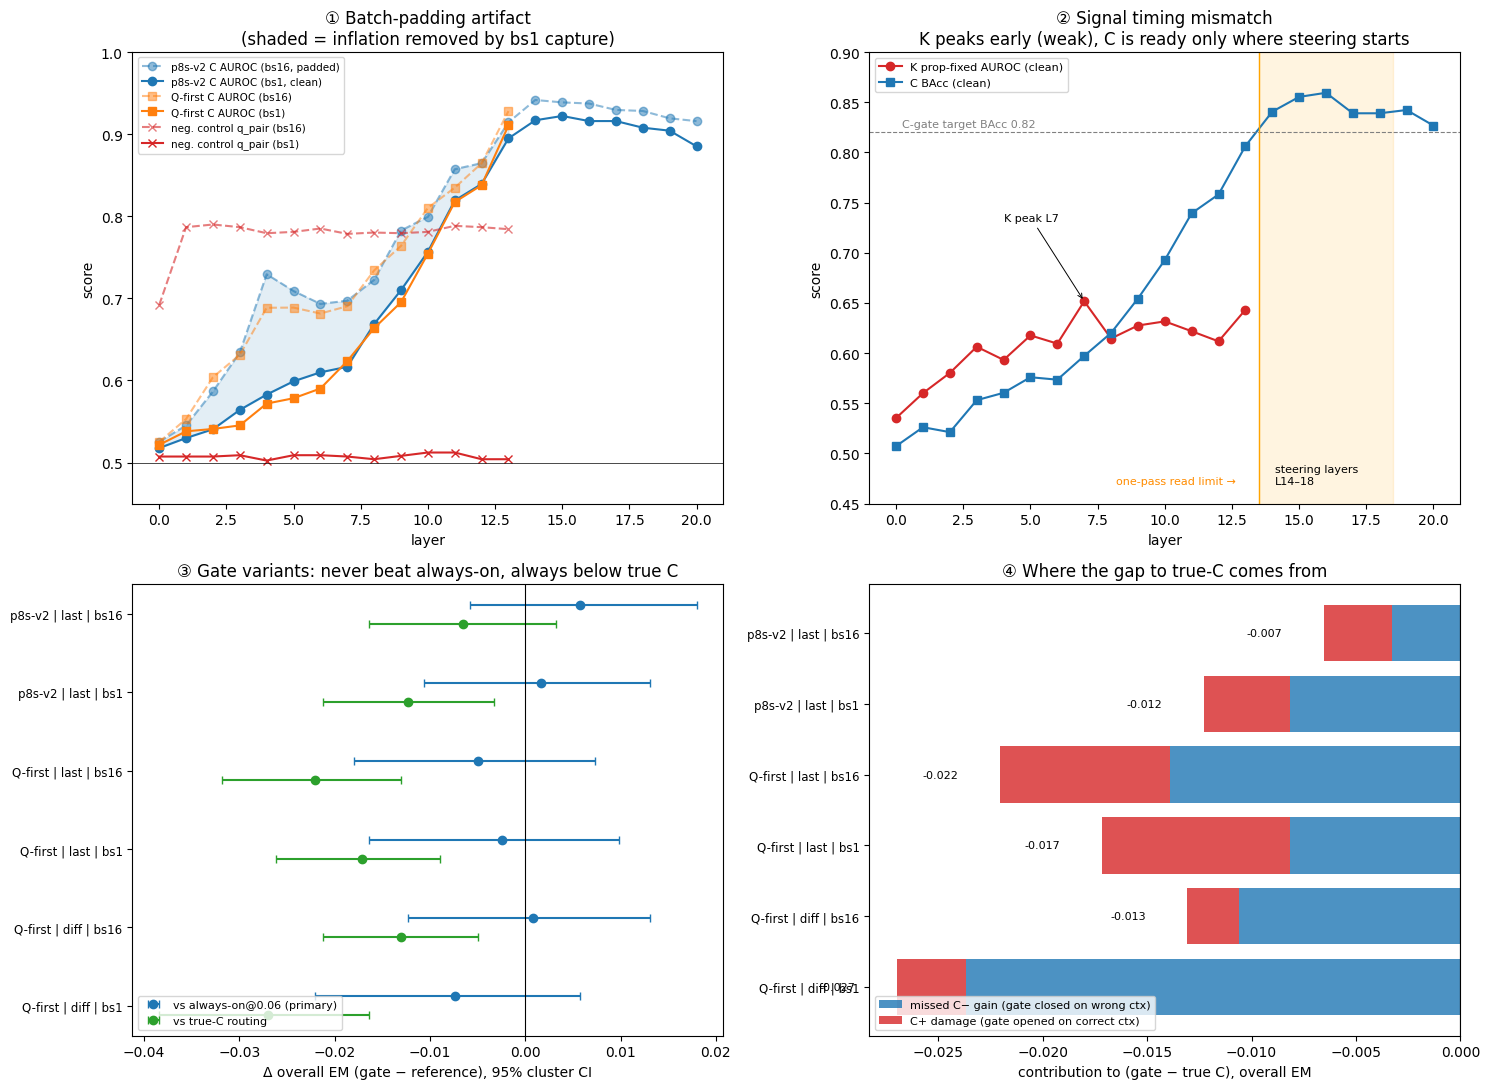

In [ ]:
## Cell 37 — A 최종 결론 시각화 (CPU, 즉시)
fig, ax = plt.subplots(2, 2, figsize=(15, 11))

# ① 패딩 흔적 보정
a = ax[0, 0]
a.plot(A1.L, A1.C_AUROC, 'o--', c='C0', alpha=.5, label='p8s-v2 C AUROC (bs16, padded)')
a.plot(A1b.L, A1b.C_AUROC, 'o-', c='C0', label='p8s-v2 C AUROC (bs1, clean)')
a.plot(A1QF.L, A1QF.last_AUROC, 's--', c='C1', alpha=.5, label='Q-first C AUROC (bs16)')
a.plot(A1QF1.L, A1QF1.last_AUROC, 's-', c='C1', label='Q-first C AUROC (bs1)')
a.plot(A1QF.L, A1QF.q_pair, 'x--', c='C3', alpha=.6, label='neg. control q_pair (bs16)')
a.plot(A1QF1.L, A1QF1.q_pair, 'x-', c='C3', label='neg. control q_pair (bs1)')
a.axhline(.5, c='k', lw=.5)
a.fill_between(A1b.L[:14], A1b.C_AUROC[:14], A1.C_AUROC[:14], color='C0', alpha=.12)
a.set(xlabel='layer', ylabel='score', ylim=(.45, 1),
      title='① Batch-padding artifact\n(shaded = inflation removed by bs1 capture)')
a.legend(fontsize=7.5, loc='upper left')

# ② 신호 시점 불일치
a = ax[0, 1]
a.plot(A1b.L[:14], A1b.K_propfixed[:14], 'o-', c='C3', label='K prop-fixed AUROC (clean)')
a.plot(A1b.L, A1b.C_BAcc, 's-', c='C0', label='C BAcc (clean)')
a.axhline(.82, c='gray', ls='--', lw=.8)
a.text(.2, .825, 'C-gate target BAcc 0.82', fontsize=8, color='gray')
a.axvspan(13.5, 18.5, color='orange', alpha=.12)
a.text(14.1, .47, 'steering layers\nL14–18', fontsize=8)
a.axvline(13.5, c='orange', lw=1)
a.text(8.2, .47, 'one-pass read limit →', fontsize=8, color='darkorange')
kL = int(A1b.K_propfixed[:14].idxmax())
a.annotate(f'K peak L{kL}', (kL, A1b.K_propfixed[kL]), (kL - 3, A1b.K_propfixed[kL] + .08),
           arrowprops=dict(arrowstyle='->', lw=.7), fontsize=8)
a.set(xlabel='layer', ylabel='score', ylim=(.45, .9),
      title='② Signal timing mismatch\nK peaks early (weak), C is ready only where steering starts')
a.legend(fontsize=8, loc='upper left')

# ③ 강건성 forest plot
def truec(picks, em_fn, base):
    tc = base.astype(float).copy()
    for r in picks.itertuples():
        if r.rho is not None and not pd.isna(r.rho):
            s = (FOLD == r.fold) & isCm
            tc[s] = em_fn(r.rho)[s]
    return tc

VAR = [('p8s-v2 | last | bs16', G_hid, pk_hid, em_of, b0),
       ('p8s-v2 | last | bs1', G1, pk1, em_of, b0),
       ('Q-first | last | bs16', G_last, pk_last, em_qf, b0q),
       ('Q-first | last | bs1', Gl1, pkl1, em_qf, b0q),
       ('Q-first | diff | bs16', G_diff, pk_diff, em_qf, b0q),
       ('Q-first | diff | bs1', Gd1, pkd1, em_qf, b0q)]
a = ax[1, 0]
ALLm = np.ones(len(m), bool)
for y, (n_, G, pk, ef, bs) in enumerate(VAR[::-1]):
    for off, ref, col, lab in [(.12, ef(0.06), 'C0', 'vs always-on@0.06 (primary)'),
                               (-.12, truec(pk, ef, bs), 'C2', 'vs true-C routing')]:
        d = G - ref
        lo, hi = ci_d(d, ALLm)
        a.errorbar(d.mean(), y + off, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt='o', c=col,
                   capsize=3, label=lab if y == 0 else None)
a.axvline(0, c='k', lw=.8)
a.set_yticks(range(len(VAR)), [v[0] for v in VAR[::-1]], fontsize=8.5)
a.set(xlabel='Δ overall EM (gate − reference), 95% cluster CI',
      title='③ Gate variants: never beat always-on, always below true C')
a.legend(fontsize=8, loc='lower left')

# ④ 참 C와의 격차 분해: 놓친 C− 이득 vs C+ 오개방 손상
a = ax[1, 1]
N = len(m)
miss, dmg = [], []
for n_, G, pk, ef, bs in VAR:
    gap = G - truec(pk, ef, bs)
    miss.append(gap[isCm].sum() / N)      # C− 행: 게이트가 안 열어서 놓친 이득 (음수)
    dmg.append(gap[~isCm].sum() / N)      # C+ 행: 잘못 열어서 생긴 손상 (음수)
ys = np.arange(len(VAR))
a.barh(ys, miss, color='C0', alpha=.8, label='missed C− gain (gate closed on wrong ctx)')
a.barh(ys, dmg, left=miss, color='C3', alpha=.8, label='C+ damage (gate opened on correct ctx)')
for y, (mm, dd) in enumerate(zip(miss, dmg)):
    a.text(mm + dd - .002, y, f'{mm + dd:+.3f}', va='center', ha='right', fontsize=8)
a.axvline(0, c='k', lw=.8)
a.set_yticks(ys, [v[0] for v in VAR], fontsize=8.5)
a.invert_yaxis()
a.set(xlabel='contribution to (gate − true C), overall EM',
      title='④ Where the gap to true-C comes from')
a.legend(fontsize=8, loc='lower left')

plt.tight_layout()
plt.savefig(ROOT / 'gen' / 'A_final_conclusion.png', dpi=150)
plt.show()

# B4 방향 비교

In [ ]:
## Cell 36 — B4: K 기반 방향 (사전등록 → w 구성 → 생성 → 비교)
import datetime as dt
PREREG_B4 = {
 'date': dt.datetime.now(dt.timezone(dt.timedelta(hours=9))).isoformat(),
 'question': 'K 상태로 만든 방향(w_K)이 행동 방향(w_v3)을 대체하거나 넘는가, 방향 특이적인가',
 'directions': {'w_K_all': 'train 전 행 K+ − K−, prop 균형, bs1 hidden L14–18',
                'w_K_Cm': 'train C− 행만 K+ − K−, prop 균형'},
 'grid': 'ρ ∈ {0.06, 0.10}, P9 전 토큰, L14–18, p8s-v2',
 'primary': 'w_K_all@0.06 − w_v3@0.06, C− ΔEM paired CI (동등/우위/열위 서술) + C+ 비열등 −0.02',
 'specificity': 'w_K_all@0.06 vs K-perm-null 10회 (fold×prop 안 질문 단위 셔플), 특이적 효과 = 실제 − perm 평균',
 'known_before': 'B·A 전체 결과. w_K 생성 결과는 미확인',
}
json.dump(PREREG_B4, open(ROOT / 'env' / 'prereg_B4.json', 'w'), ensure_ascii=False, indent=1)
print('prereg md5:', md5(open(ROOT / 'env' / 'prereg_B4.json', 'rb').read()))

def w_from(rows_mask_fn, label):
    """fold별 prop 균형 평균차 (+ = label True 쪽)"""
    Wd = {}
    for k in range(5):
        tr = rows_mask_fn(k)
        Wd[k] = {L: pbd(H1[:, L].astype(np.float32), tr & label, tr & ~label)[0] for L in LAY}
    return Wd

W_K_all = w_from(lambda k: FOLD != k, K)
W_K_Cm = w_from(lambda k: (FOLD != k) & isCm, K)
print('cos(w_K_all, w_v3) fold0 L14–18:', [round(float(W_K_all[0][L] @ W3[0][L]), 3) for L in LAY])
print('cos(w_K_Cm,  w_v3) fold0 L14–18:', [round(float(W_K_Cm[0][L] @ W3[0][L]), 3) for L in LAY])

def run_w(tag, rho, Wd):
    f = ROOT / 'gen' / f'B4_{tag}.parquet'
    if f.exists():
        return pd.read_parquet(f)
    t0, rec = time.time(), []
    for k in range(5):
        set_steer(k, rho, Wd[k])
        rec += [dict(rid=r, raw=x, n_tok=n, ids=i) for r, (x, n, i) in gen_rows_s(FOLD_ROWS[k]).items()]
    ST.d = None
    df = score(pd.DataFrame(rec))
    df.to_parquet(f, index=False)
    print(f'B4_{tag}: {time.time()-t0:.0f}s')
    return df

R4 = {}
for name, Wd in [('wKall', W_K_all), ('wKCm', W_K_Cm)]:
    for rho in (0.06, 0.10):
        R4[(name, rho)] = run_w(f'{name}_r{rho:.2f}', rho, Wd)

# K perm-null: fold × prop 안에서 질문 단위로 K 셔플
qK = dict(zip(m.question, K))
PERM = []
for p_i in range(10):
    rng = np.random.default_rng(1000 + p_i)
    Wd = {}
    for k in range(5):
        tr = FOLD != k
        qdf_ = m[tr].drop_duplicates('question')[['question', 'prop']]
        newK = {}
        for _, g in qdf_.groupby('prop'):
            ks = np.array([qK[q] for q in g.question])
            newK.update(dict(zip(g.question, rng.permutation(ks))))
        Kp = np.array([newK.get(q, False) for q in m.question])
        Wd[k] = {L: pbd(H1[:, L].astype(np.float32), tr & Kp, tr & ~Kp)[0] for L in LAY}
    PERM.append(run_w(f'permK{p_i}_r0.06', 0.06, Wd).em.values)

# 결과
def row(name, v, ref=b0):
    d = v - ref
    r = {'arm': name}
    for lab, sel in [('C−', isCm), ('C+', ~isCm)]:
        lo, hi = ci_d(d, sel)
        r[lab] = f'{d[sel].mean():+.4f} [{lo:+.3f}, {hi:+.3f}]'
    for c in ['K+C+', 'K+C−', 'K−C+', 'K−C−']:
        s = (m.cell == c).values
        r[c] = int(d[s].sum())
    return r

tab = [row('w_v3 @0.06', em_of(0.06)), row('w_v3 @0.10', em_of(0.10))]
for (name, rho), df in R4.items():
    tab.append(row(f'{name} @{rho:.2f}', df.em.values))
print(pd.DataFrame(tab).to_string(index=False))

print('\n[주] w_K_all@0.06 − w_v3@0.06 (C− 행)')
d = R4[('wKall', 0.06)].em.values - em_of(0.06)
lo, hi = ci_d(d, isCm)
print(f'  C− 차이 {d[isCm].mean():+.4f} [{lo:+.4f}, {hi:+.4f}]')

perm_cm = np.array([(v - b0)[isCm].mean() for v in PERM])
real_cm = (R4[('wKall', 0.06)].em.values - b0)[isCm].mean()
print(f'\n[특이성] w_K_all@0.06 C− {real_cm:+.4f} | perm 평균 {perm_cm.mean():+.4f} '
      f'(최대 {perm_cm.max():+.4f}) | 특이적 효과 {real_cm - perm_cm.mean():+.4f} | 실제 > perm 전부: {bool((real_cm > perm_cm).all())}')

prereg md5: 15ec949b26fc12fb5e48897a95190706
cos(w_K_all, w_v3) fold0 L14–18: [0.696, 0.789, 0.791, 0.764, 0.764]
cos(w_K_Cm,  w_v3) fold0 L14–18: [0.739, 0.833, 0.838, 0.819, 0.824]
B4_wKall_r0.06: 48s
B4_wKall_r0.10: 50s
B4_wKCm_r0.06: 49s
B4_wKCm_r0.10: 58s
B4_permK0_r0.06: 50s
B4_permK1_r0.06: 50s
B4_permK2_r0.06: 50s
B4_permK3_r0.06: 49s
B4_permK4_r0.06: 49s
B4_permK5_r0.06: 50s
B4_permK6_r0.06: 49s
B4_permK7_r0.06: 50s
B4_permK8_r0.06: 49s
B4_permK9_r0.06: 50s
        arm                       C−                       C+  K+C+  K+C−  K−C+  K−C−
 w_v3 @0.06 +0.1291 [+0.101, +0.158] +0.0000 [-0.018, +0.018]     3    66    -3    13
 w_v3 @0.10 +0.1650 [+0.134, +0.199] -0.0261 [-0.051, +0.002]    -5    82   -11    19
wKall @0.06 +0.1160 [+0.090, +0.144] +0.0131 [-0.003, +0.029]     5    60     3    11
wKall @0.10 +0.1422 [+0.109, +0.175] -0.0212 [-0.047, +0.005]    -4    73    -9    14
 wKCm @0.06 +0.1209 [+0.095, +0.150] +0.0098 [-0.007, +0.026]     6    64     0    10
 wKCm @0.10 +

# A2/A3 게이트 비교

# A4·A5 + nested 검증